# Robustness reanalysis: Studies 1A, 1B, 1C, 2A and 2B

Companion notebook for *Lexical Compression and Closed-Class Framing in Ideological Discourse: A Multi-Corpus
Methodological and Specification-Curve Audit*. Every table in the manuscript is produced by a cell in this
notebook. Nothing here changes the feature definitions: the kernel below is copied verbatim from
`Master_V3_Five_Corpus_Pipeline.ipynb` (and checked against `src/feature_extraction.py`).

**Study 1A.** Bias ratings belong to outlets, not articles, and the five largest outlets on each side supply
50–67% of the articles. The paper's article-level tests therefore treat many articles from one outlet as
independent. This section (i) matches articles by AllSides story (the roundup `title`) rather than by first
subject tag, (ii) drops AllSides' own roundup title from each window so only outlet-written text is measured,
and (iii) estimates the partisan contrasts with the outlet as the unit of analysis.

**Studies 1B and 1C (Tables 3 and 4).** Computed from the exported matrices with the manuscript's stated cut-offs:
effect sizes with confidence intervals, FDR-corrected tests, equivalence tests, the trait-vs-state comparison for
Stormfront authors, and author-grouped classification AUCs with bootstrap confidence intervals.

**Study 2A.** The crisis effect depends on several analytic choices. This section estimates it under every
combination of 8 crisis definitions × 3 delivery-mode codings × 4 time trends × 3 estimators
(288 specifications per feature), then runs a joint test that keeps the run structure of the crisis series.

**Study 2B.** The within-user coupling effects are re-estimated with random slopes, with user fixed effects and a
wild cluster bootstrap, without the most prolific accounts, and across a specification curve; the trait-vs-state
claim is tested directly.

Runs in Google Colab or from `notebooks/` inside the repository. Runtime is about 10–12 minutes on Colab.
Outputs (tables as CSV, figures as PDF and PNG) go to `robustness_outputs/`.

In [1]:
import os, re, math, zlib, subprocess, warnings, itertools, time
from collections import Counter
import numpy as np
import pandas as pd
import patsy
import scipy.sparse as sp
import statsmodels.formula.api as smf
from scipy import stats
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
OUT = "robustness_outputs"
os.makedirs(OUT, exist_ok=True)
RNG = np.random.default_rng(20261021)


def ensure_clone(url, path):
    if not os.path.exists(path):
        subprocess.run(["git", "clone", "-q", "--depth", "1", url, path], check=True)
    return path


def find_repo_file(rel):
    """Use the repo's data/ folder if this notebook runs inside the repo; otherwise clone the repo."""
    for base in ["..", ".", "inct-empirical-validation"]:
        p = os.path.join(base, rel)
        if os.path.exists(p):
            return p
    ensure_clone("https://github.com/KashShahzad/inct-empirical-validation.git", "inct-empirical-validation")
    return os.path.join("inct-empirical-validation", rel)


QBIAS_CSV = os.path.join(ensure_clone("https://github.com/irgroup/Qbias.git", "Qbias"),
                         "allsides_balanced_news_headlines-texts.csv")
PAPER_1A_CSV = find_repo_file("data/study1a_allsides_balanced_w52.csv")
SOTU_CSV = find_repo_file("data/study2a_sotu_speeches_1790_2008.csv")
print("Data:", QBIAS_CSV, "|", PAPER_1A_CSV, "|", SOTU_CSV)

# Figure style: recessive axes and grid, ink-coloured text, colour reserved for data.
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#a8a7a1"
plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 9, "axes.edgecolor": INK2, "axes.linewidth": 0.6,
    "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 300,
    "savefig.bbox": "tight", "legend.frameon": False,
})


def save(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(OUT, f"{name}.{ext}"))

Data: Qbias/allsides_balanced_news_headlines-texts.csv | inct-empirical-validation/data/study1a_allsides_balanced_w52.csv | inct-empirical-validation/data/study2a_sotu_speeches_1790_2008.csv


## Feature kernel (verbatim from `Master_V3_Five_Corpus_Pipeline.ipynb`)

The cell after the kernel checks that `src/feature_extraction.py` in the repository returns identical values.

In [2]:
WE_US_PRONOUNS = {"we", "us", "our", "ours", "ourselves"}
THEY_THEM_PRONOUNS = {"they", "them", "their", "theirs", "themselves"}
US_THEM_PRONOUNS = WE_US_PRONOUNS | THEY_THEM_PRONOUNS
ABSOLUTIST_LEXICON = {
    "absolutely", "all", "always", "complete", "completely", "constant", "constantly",
    "definitely", "entire", "ever", "every", "everyone", "everything", "full", "must",
    "never", "nothing", "totally", "whole"
}
STOPWORDS = {
    "the", "and", "of", "to", "in", "is", "that", "it", "for", "as", "with", "on",
    "was", "be", "by", "at", "this", "are", "from", "or", "an", "have", "had", "has",
    "but", "which", "one", "would", "were", "there", "been", "if", "more", "when", "so",
    "you", "your", "yours", "yourself", "yourselves", "he", "him", "his", "himself",
    "she", "her", "hers", "herself", "it", "its", "itself", "me", "my", "mine", "myself",
    "not", "no", "nor", "do", "does", "did", "doing", "can", "could", "should", "will",
    "shall", "may", "might", "who", "whom", "whose", "what", "where", "why", "how",
    "about", "into", "through", "during", "before", "after", "above", "below", "between",
    "under", "again", "further", "then", "once", "here", "any", "both", "each", "few",
    "other", "some", "such", "only", "own", "same", "than", "too", "very", "just", "now"
} | US_THEM_PRONOUNS | ABSOLUTIST_LEXICON


def extract_rate_distortion_features(tokens, min_content=12):
    if not tokens:
        return None
    W = float(len(tokens))
    content_tokens = [t for t in tokens if t not in STOPWORDS]
    N_c = float(len(content_tokens))
    if N_c < min_content:
        return None
    counts_c = Counter(content_tokens)
    V_c = len(counts_c)
    if V_c <= 3:
        return None
    H_c = -sum((c / N_c) * math.log2(c / N_c) for c in counts_c.values())
    D_KL_global = math.log2(V_c) - H_c
    top3 = {w for w, _ in counts_c.most_common(3)}
    tail_tokens = [t for t in content_tokens if t not in top3]
    counts_tail = Counter(tail_tokens)
    N_tail, V_tail = float(len(tail_tokens)), len(counts_tail)
    if V_tail > 2 and N_tail > 5:
        H_tail = -sum((c / N_tail) * math.log2(c / N_tail) for c in counts_tail.values())
        D_KL_tail = math.log2(V_tail) - H_tail
    else:
        D_KL_tail = 0.0
    freq_spec = Counter(counts_c.values())
    M2 = sum((m ** 2) * v_m for m, v_m in freq_spec.items())
    yules_K = 10000.0 * (M2 - N_c) / (N_c ** 2)
    raw_bytes = " ".join(content_tokens).encode("utf-8")
    R_lz = 1.0 - (len(zlib.compress(raw_bytes, level=9)) / float(len(raw_bytes)))
    counts_all = Counter(tokens)
    bigrams = list(zip(tokens[:-1], tokens[1:]))
    bg_red = 1.0 - (len(set(bigrams)) / float(len(bigrams))) if bigrams else 0.0
    bg_counts = Counter(bigrams)
    H_cond = -sum((c / len(bigrams)) * math.log2(c / counts_all[bg[0]]) for bg, c in bg_counts.items()) if bigrams else 0.0
    abs_dens = sum(1 for t in tokens if t in ABSOLUTIST_LEXICON) / W
    we_dens = sum(1 for t in tokens if t in WE_US_PRONOUNS) / W
    they_dens = sum(1 for t in tokens if t in THEY_THEM_PRONOUNS) / W
    return {
        "H_Content": H_c, "D_KL_Global": D_KL_global, "D_KL_Tail": D_KL_tail, "Yules_K": yules_K,
        "R_LZ_Content": R_lz, "Bigram_Redundancy": bg_red, "H_Conditional": H_cond,
        "Absolutist_Density": abs_dens, "UsThem_Pronoun_Density": we_dens + they_dens,
        "We_Us_Density": we_dens, "They_Them_Density": they_dens
    }


def cohens_d(x0, x1):
    x0, x1 = np.asarray(x0, float), np.asarray(x1, float)
    s0, s1 = np.std(x0, ddof=1), np.std(x1, ddof=1)
    n0, n1 = len(x0), len(x1)
    pooled = np.sqrt(((n0 - 1) * s0**2 + (n1 - 1) * s1**2) / max(1, (n0 + n1 - 2)))
    return float((np.mean(x1) - np.mean(x0)) / (pooled + 1e-12))


def zscore(s):
    s = pd.Series(s, dtype=float)
    return (s - s.mean()) / s.std()

In [3]:
import importlib.util
_src = find_repo_file("src/feature_extraction.py")
_spec = importlib.util.spec_from_file_location("repo_feature_extraction", _src)
_repo_fe = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_repo_fe)
_samples = [
    "we must always defend our people because they will never stop attacking our nation and their allies across "
    "every city while the government does nothing at all about the crisis facing ordinary workers today",
    "the senate passed the bill on tuesday after weeks of negotiation and the president said he would sign it "
    "quickly although critics don t think the measure goes far enough to address rising costs for families",
]
_match = all(_repo_fe.extract_rate_distortion_features(t.split(), min_content=10)
             == extract_rate_distortion_features(t.split(), min_content=10) for t in _samples)
print(f"src/feature_extraction.py returns identical features to this kernel: {_match}")

src/feature_extraction.py returns identical features to this kernel: True


# Part 1 — Study 1A at the outlet level (Tables 1 and 2, Figure 1)

In the Qbias file, `title` is **AllSides' roundup title**, shared by the Left, Center and Right articles on
the same story; `heading` is the outlet's headline; `text` is the outlet's opening paragraphs. The paper's
windows are the first 52 tokens of `title + heading + text`, and its "topic" is the first subject tag
(e.g. `Protests` for a Chicago gun-violence story).

Below, **story = AllSides roundup title** (the actual matching unit), and the primary window drops the shared
AllSides title so only outlet-written text is measured. The paper's window definition is kept as a sensitivity check.

In [4]:
raw = pd.read_csv(QBIAS_CSV, on_bad_lines="skip")
raw["bias_rating"] = raw["bias_rating"].astype(str).str.strip().str.lower()
raw = raw[raw["bias_rating"].isin(["left", "center", "right"])].copy()


def build_windows(include_allsides_title, W=52, min_content=13):
    rows = []
    for title, heading, text, source, tags, bias in zip(raw["title"], raw["heading"], raw["text"],
                                                        raw["source"], raw["tags"], raw["bias_rating"]):
        parts = ([title] if include_allsides_title else []) + [heading, text]
        full = " ".join("" if pd.isna(p) else str(p) for p in parts)
        toks = re.findall(r"\b[a-z]{2,}\b", re.sub(r"http\S+|@\S+", "", full.lower()))
        if len(toks) >= W:
            f = extract_rate_distortion_features(toks[:W], min_content=min_content)
            if f:
                f.update(Bias=bias,
                         Outlet=str(source).strip() if pd.notna(source) else "Unknown",
                         Story=str(title),
                         Topic=str(tags).split(",")[0].strip() if pd.notna(tags) else "General")
                rows.append(f)
    d = pd.DataFrame(rows)
    d["Right"] = (d["Bias"] == "right").astype(int)
    d["Partisan"] = d["Bias"].isin(["left", "right"]).astype(int)
    return d


t0 = time.time()
win_paper = build_windows(include_allsides_title=True)
win_outlet = build_windows(include_allsides_title=False)
print(f"Built windows in {time.time() - t0:.0f}s")

# Sanity check: the paper-definition windows must reproduce data/study1a_allsides_balanced_w52.csv exactly.
paper_csv = pd.read_csv(PAPER_1A_CSV)
same = len(paper_csv) == len(win_paper) and np.allclose(paper_csv["R_LZ_Content"], win_paper["R_LZ_Content"])
print(f"Paper windows reproduce the repository CSV: {same} (n = {len(win_paper):,})")
print(f"Outlet-text-only windows: n = {len(win_outlet):,}")
print(f"Stories (AllSides roundups): {win_paper.Story.nunique():,} | first-tag 'topics': {win_paper.Topic.nunique()} | "
      f"outlets: {win_paper.Outlet.nunique()}")
for b in ["left", "center", "right"]:
    vc = win_outlet[win_outlet.Bias == b].Outlet.value_counts()
    print(f"  {b:6s} {vc.size:3d} outlets; 5 largest supply {100 * vc.head(5).sum() / vc.sum():.0f}% of articles: "
          f"{', '.join(vc.head(5).index)}")

Built windows in 4s
Paper windows reproduce the repository CSV: True (n = 16,366)
Outlet-text-only windows: n = 15,038
Stories (AllSides roundups): 6,447 | first-tag 'topics': 553 | outlets: 443
  left   156 outlets; 5 largest supply 49% of articles: CNN (Online News), New York Times (News), Washington Post, Politico, NPR (Online News)
  center 154 outlets; 5 largest supply 66% of articles: The Hill, Wall Street Journal (News), Reuters, Axios, CNBC
  right  127 outlets; 5 largest supply 61% of articles: Fox News (Online News), Washington Examiner, Washington Times, New York Post (News), National Review


### Estimators

For each feature and contrast (Right vs Left; Left+Right vs Center), outcome z-scored:

| Column | What it does | Unit that counts |
|---|---|---|
| **Paper** | Right vs Left: article-level Cohen's *d* and Mann-Whitney *p*. Partisan vs Center: mixed model with a random intercept for the first subject tag (as in Table 1). | article |
| **Outlet RE** | Mixed model with a random intercept per outlet. | outlet (shrunk) |
| **Story FE, wild bootstrap** | Within-story comparison (story fixed effects), every article weighted equally; *p* from a wild cluster bootstrap by outlet (Webb weights, 999 draws), which stays valid when a few clusters dominate. | article, matched story |
| **Outlet effects** | Two-way fixed effects (story + outlet) estimated jointly, then the estimated outlet effects compared between groups with a Welch *t*-test (outlets with ≥ 10 articles). Reported as the difference in mean outlet effect, in SD units. | outlet (equal weight), story-adjusted |

The outlet random-intercept model does not adjust for story; the last two columns do. The story-FE column weights
every article equally (large outlets dominate); the outlet-effects column gives every outlet one vote.
Two-way FE is used rather than "subtract the story mean, then average by outlet", because a small outlet's
story-demeaned score would otherwise absorb the effects of the large outlets it was paired with.

In [5]:
FEATS_1A = ["H_Content", "D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content", "H_Conditional",
            "Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"]
WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])


def contrast_frame(d, contrast):
    if contrast == "Right vs Left":
        return d[d.Bias.isin(["left", "right"])].copy(), "Right"
    return d.copy(), "Partisan"


def paper_test(d, f, contrast):
    D, x = contrast_frame(d, contrast)
    if contrast == "Right vs Left":
        a, b = D[D[x] == 0][f], D[D[x] == 1][f]
        return cohens_d(a, b), stats.mannwhitneyu(a, b).pvalue
    D["Z"] = zscore(D[f])
    m = smf.mixedlm(f"Z ~ {x}", D, groups=D["Topic"]).fit(reml=True)
    return m.params[x], m.pvalues[x]


def outlet_re(d, f, contrast):
    D, x = contrast_frame(d, contrast)
    D["Z"] = zscore(D[f])
    m = smf.mixedlm(f"Z ~ {x}", D, groups=D["Outlet"]).fit(reml=True)
    return m.params[x], m.pvalues[x]


def story_fe_wild(d, f, contrast, B=999, chunk=250):
    D, x = contrast_frame(d, contrast)
    D["Z"] = zscore(D[f])
    D = D[D.groupby("Story")[x].transform("nunique") > 1]          # stories where the contrast varies
    s_idx = pd.factorize(D["Story"])[0]
    g_idx = pd.factorize(D["Outlet"])[0]
    n, S, G = len(D), s_idx.max() + 1, g_idx.max() + 1
    Ms = sp.csr_matrix((np.ones(n), (np.arange(n), s_idx)), shape=(n, S))
    Mg = sp.csr_matrix((np.ones(n), (np.arange(n), g_idx)), shape=(n, G))
    cnt = np.asarray(Ms.sum(0)).ravel()

    def demean(A):                                                   # A: (k, n) -> subtract story means row-wise
        means = (Ms.T @ A.T) / cnt[:, None]                          # (S, k)
        return A - (Ms @ means).T

    y = demean(D["Z"].values[None, :])[0]
    xd = demean(D[x].values.astype(float)[None, :])[0]
    sxx = xd @ xd

    def t_stats(Y):                                                  # Y: (k, n) within-story outcomes
        beta = (Y @ xd) / sxx
        E = Y - beta[:, None] * xd[None, :]
        scores = Mg.T @ (E * xd[None, :]).T                          # (G, k) per-outlet score sums
        V = (G / (G - 1)) * (scores**2).sum(0) / sxx**2
        return beta, beta / np.sqrt(V)

    beta, t = t_stats(y[None, :])
    tb = []
    for start in range(0, B, chunk):
        k = min(chunk, B - start)
        w = WEBB[RNG.integers(0, 6, size=(k, G))]
        Ystar = demean(w[:, g_idx] * y[None, :])                     # restricted (beta = 0) wild draws
        tb.append(t_stats(Ystar)[1])
    tb = np.concatenate(tb)
    p = (1 + np.sum(np.abs(tb) >= np.abs(t[0]))) / (B + 1)
    return beta[0], p, n


def twoway_outlet_effects(D, z, iters=5000, tol=1e-10):
    """Story + outlet fixed effects by alternating projections; returns outlet effects (up to a constant)."""
    s = pd.factorize(D["Story"])[0]
    o, names = pd.factorize(D["Outlet"])
    cs, co = np.bincount(s), np.bincount(o)
    oe = np.zeros(o.max() + 1)
    for _ in range(iters):
        se = np.bincount(s, weights=z - oe[o]) / cs
        new = np.bincount(o, weights=z - se[s]) / co
        done = np.max(np.abs(new - oe)) < tol
        oe = new
        if done:
            break
    return pd.Series(oe, index=names)


def outlet_effects(d, f, contrast, min_articles=10):
    D, x = contrast_frame(d, contrast)
    fe = twoway_outlet_effects(D, zscore(D[f]).values)
    O = D.groupby("Outlet").agg(x=(x, "first"), n=(x, "size")).join(fe.rename("fe"))
    O = O[O.n >= min_articles]
    a, b = O[O.x == 0].fe, O[O.x == 1].fe
    return b.mean() - a.mean(), stats.ttest_ind(a, b, equal_var=False).pvalue, len(a), len(b), O


def run_1a(d, label):
    rows = []
    for contrast in ["Right vs Left", "Partisan vs Center"]:
        for f in FEATS_1A:
            pe, pp = paper_test(d, f, contrast)
            re_b, re_p = outlet_re(d, f, contrast)
            fe_b, fe_p, fe_n = story_fe_wild(d, f, contrast)
            oe_d, oe_p, n0, n1, _ = outlet_effects(d, f, contrast)
            rows.append(dict(window=label, contrast=contrast, feature=f,
                             paper_est=pe, paper_p=pp, outletRE_beta=re_b, outletRE_p=re_p,
                             storyFE_beta=fe_b, storyFE_wild_p=fe_p, storyFE_n=fe_n,
                             outletEffects_diff=oe_d, outletEffects_p=oe_p, n_outlets_0=n0, n_outlets_1=n1))
    return pd.DataFrame(rows)


t0 = time.time()
res_1a = pd.concat([run_1a(win_outlet, "outlet text only (primary)"),
                    run_1a(win_paper, "paper windows (AllSides title included)")], ignore_index=True)
res_1a.to_csv(os.path.join(OUT, "study1a_outlet_level_results.csv"), index=False)
print(f"Study 1A models finished in {time.time() - t0:.0f}s")


def fmt_p(p):
    return f"{p:.1e}" if p < 0.001 else f"{p:.3f}"


def show_1a(window, contrast):
    T = res_1a[(res_1a.window == window) & (res_1a.contrast == contrast)]
    first = "Paper: d (MW p)" if contrast == "Right vs Left" else "Paper: tag-RE β (p)"
    out = pd.DataFrame({
        "feature": T.feature,
        first: [f"{e:+.3f} ({fmt_p(p)})" for e, p in zip(T.paper_est, T.paper_p)],
        "Outlet RE β (p)": [f"{e:+.3f} ({fmt_p(p)})" for e, p in zip(T.outletRE_beta, T.outletRE_p)],
        "Story FE β (wild p)": [f"{e:+.3f} ({fmt_p(p)})" for e, p in zip(T.storyFE_beta, T.storyFE_wild_p)],
        "Outlet effects Δ (p)": [f"{e:+.3f} ({fmt_p(p)})" for e, p in zip(T.outletEffects_diff, T.outletEffects_p)],
    })
    n0, n1 = int(T.n_outlets_0.iloc[0]), int(T.n_outlets_1.iloc[0])
    print(f"\n{contrast} — {window}   [outlet-effects test: {n1} vs {n0} outlets with ≥10 articles]")
    print(out.to_string(index=False))


for c in ["Right vs Left", "Partisan vs Center"]:
    show_1a("outlet text only (primary)", c)
for c in ["Right vs Left", "Partisan vs Center"]:
    show_1a("paper windows (AllSides title included)", c)

Study 1A models finished in 132s

Right vs Left — outlet text only (primary)   [outlet-effects test: 28 vs 44 outlets with ≥10 articles]
               feature  Paper: d (MW p) Outlet RE β (p) Story FE β (wild p) Outlet effects Δ (p)
             H_Content   -0.026 (0.149)  -0.048 (0.338)      -0.022 (0.702)       -0.061 (0.473)
           D_KL_Global +0.177 (1.5e-22)  +0.032 (0.664)      +0.174 (0.002)       +0.112 (0.180)
             D_KL_Tail +0.218 (5.8e-32)  -0.003 (0.967)      +0.203 (0.002)       +0.074 (0.424)
               Yules_K +0.156 (5.5e-19)  +0.040 (0.575)      +0.149 (0.015)       +0.090 (0.288)
          R_LZ_Content +0.235 (2.3e-39)  +0.044 (0.613)      +0.216 (0.002)       +0.068 (0.497)
         H_Conditional +0.062 (7.2e-04)  +0.031 (0.522)      +0.064 (0.058)       +0.054 (0.413)
    Absolutist_Density   +0.029 (0.479)  +0.101 (0.067)      +0.037 (0.292)       +0.126 (0.090)
UsThem_Pronoun_Density   -0.019 (0.698)  +0.113 (0.132)      -0.023 (0.746)       -0.02

### Is the Right–Left difference a property of a few outlets?

Two versions of the Right − Left contrast, recomputed after removing the *k* largest outlets from each side
(*k* = 0…10), on the primary (outlet-text) windows:
- **unmatched**: the paper's statistic, article-level Cohen's *d* with no story matching;
- **within story**: the story fixed-effects estimate (articles on the same AllSides story compared with each
  other), 95% CI from outlet-clustered standard errors.

If the difference were driven by a handful of high-volume outlets, both lines would fall to zero as they are removed.

In [6]:
def within_story(D, f, sd_ref):
    D = D[D.groupby("Story")["Right"].transform("nunique") > 1]
    z = (D[f] - D[f].mean()) / sd_ref
    yd = (z - z.groupby(D["Story"]).transform("mean")).values
    xd = (D["Right"] - D.groupby("Story")["Right"].transform("mean")).values
    g = pd.factorize(D["Outlet"])[0]
    G_ = g.max() + 1
    sxx = xd @ xd
    beta = (xd @ yd) / sxx
    scores = np.bincount(g, weights=xd * (yd - beta * xd), minlength=G_)
    se = np.sqrt((G_ / (G_ - 1)) * (scores**2).sum() / sxx**2)
    return beta, se


def leave_top_k(d, f, kmax=10):
    D = d[d.Bias.isin(["left", "right"])]
    sd_ref = D[f].std()
    order = {b: list(D[D.Bias == b].Outlet.value_counts().index) for b in ["left", "right"]}
    rows = []
    for k in range(kmax + 1):
        E = D[~D.Outlet.isin(set(order["left"][:k]) | set(order["right"][:k]))]
        a, b = E[E.Bias == "left"][f], E[E.Bias == "right"][f]
        dd, n0, n1 = cohens_d(a, b), len(a), len(b)
        se_d = np.sqrt((n0 + n1) / (n0 * n1) + dd**2 / (2 * (n0 + n1)))
        bw, se_w = within_story(E, f, sd_ref)
        rows.append(dict(feature=f, k=k, unmatched_d=dd, unmatched_lo=dd - 1.96 * se_d, unmatched_hi=dd + 1.96 * se_d,
                         within_beta=bw, within_lo=bw - 1.96 * se_w, within_hi=bw + 1.96 * se_w,
                         share_articles_kept=len(E) / len(D)))
    return pd.DataFrame(rows)


ltk = pd.concat([leave_top_k(win_outlet, f) for f in ["R_LZ_Content", "D_KL_Tail"]], ignore_index=True)
ltk.to_csv(os.path.join(OUT, "study1a_leave_top_k_outlets.csv"), index=False)
print(ltk[["feature", "k", "unmatched_d", "within_beta", "within_lo", "within_hi", "share_articles_kept"]]
      .round(3).to_string(index=False))

     feature  k  unmatched_d  within_beta  within_lo  within_hi  share_articles_kept
R_LZ_Content  0        0.235        0.216      0.139      0.293                1.000
R_LZ_Content  1        0.220        0.204      0.128      0.280                0.820
R_LZ_Content  2        0.148        0.145      0.071      0.219                0.703
R_LZ_Content  3        0.153        0.166      0.085      0.247                0.590
R_LZ_Content  4        0.100        0.189      0.097      0.281                0.518
R_LZ_Content  5        0.072        0.193      0.082      0.304                0.456
R_LZ_Content  6        0.161        0.267      0.166      0.367                0.397
R_LZ_Content  7        0.191        0.324      0.216      0.431                0.341
R_LZ_Content  8        0.106        0.248      0.157      0.338                0.296
R_LZ_Content  9        0.101        0.247      0.161      0.333                0.258
R_LZ_Content 10        0.087        0.236      0.144      0.328  

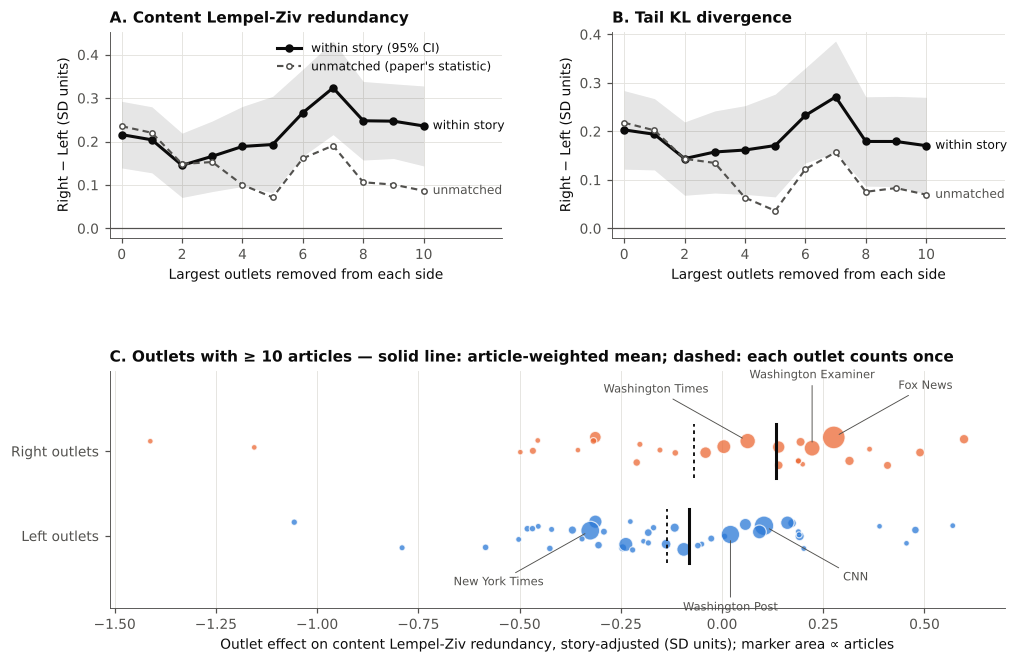

In [7]:
# Figure R1: leave-top-k curves (A, B) and story-adjusted outlet effects (C), primary outlet-text windows.
fig = plt.figure(figsize=(10.5, 6.8))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.15], hspace=0.6, wspace=0.28)
names = {"R_LZ_Content": "Content Lempel-Ziv redundancy", "D_KL_Tail": "Tail KL divergence"}
for i, f in enumerate(["R_LZ_Content", "D_KL_Tail"]):
    ax = fig.add_subplot(gs[0, i])
    T = ltk[ltk.feature == f]
    ax.axhline(0, color=INK2, lw=0.8)
    ax.fill_between(T.k, T.within_lo, T.within_hi, color=INK, alpha=0.10, lw=0)
    ax.plot(T.k, T.within_beta, color=INK, lw=2, marker="o", ms=4.5, label="within story (95% CI)")
    ax.plot(T.k, T.unmatched_d, color=INK2, lw=1.4, ls=(0, (3, 2)), marker="o", ms=3.5, mfc="white",
            label="unmatched (paper's statistic)")
    ax.text(10.3, T.within_beta.iloc[-1], "within story", fontsize=8, color=INK, va="center")
    ax.text(10.3, T.unmatched_d.iloc[-1], "unmatched", fontsize=8, color=INK2, va="center")
    ax.set_xlim(-0.4, 12.6)
    ax.set_title(f"{'AB'[i]}. {names[f]}", loc="left", fontsize=10, fontweight="bold")
    ax.set_xlabel("Largest outlets removed from each side")
    ax.set_ylabel("Right − Left (SD units)")
    ax.set_xticks(range(0, 11, 2))
    if i == 0:
        ax.legend(loc="upper right", fontsize=8)

ax = fig.add_subplot(gs[1, :])
_, _, _, _, O = outlet_effects(win_outlet, "R_LZ_Content", "Right vs Left")
D = win_outlet[win_outlet.Bias.isin(["left", "right"])]
for row, (xval, col) in enumerate([(0, BLUE), (1, ORANGE)]):
    S = O[O.x == xval]
    jitter = RNG.uniform(-0.17, 0.17, len(S))
    ax.scatter(S.fe, row + jitter, s=12 + S.n / 6, color=col, alpha=0.75, edgecolor="white", linewidth=0.8, zorder=3)
    art_mean = np.average(S.fe, weights=S.n)
    ax.plot([art_mean] * 2, [row - 0.32, row + 0.32], color=INK, lw=2, zorder=4)
    ax.plot([S.fe.mean()] * 2, [row - 0.32, row + 0.32], color=INK, lw=1.2, ls=(0, (2, 2)), zorder=4)
    top3 = S.sort_values("n", ascending=False).head(3).sort_values("fe")
    for j, (name, r) in enumerate(top3.iterrows()):
        nm = re.sub(r"\s*\((News|Online News|Opinion)\)", "", name)
        dy = (30 + 14 * (j % 2)) if row == 1 else -(30 + 14 * (j % 2))      # Right labels above, Left labels below
        ax.annotate(nm, (r.fe, row + jitter[S.index.get_loc(name)]), xytext=(-60 + 60 * j, dy),
                    textcoords="offset points", ha="center", va="bottom" if row == 1 else "top", fontsize=7.5, color=INK2,
                    arrowprops=dict(arrowstyle="-", color=INK2, lw=0.6, shrinkA=1, shrinkB=4))
ax.set_yticks([0, 1]); ax.set_yticklabels(["Left outlets", "Right outlets"])
ax.set_ylim(-0.85, 1.95)
ax.set_xlabel("Outlet effect on content Lempel-Ziv redundancy, story-adjusted (SD units); marker area ∝ articles")
ax.set_title("C. Outlets with ≥ 10 articles — solid line: article-weighted mean; dashed: each outlet counts once",
             loc="left", fontsize=10, fontweight="bold")
ax.grid(axis="y", visible=False)
save(fig, "Figure_R1_Study1A_outlet_level")
plt.show()

# Part 2 — Studies 1B and 1C (Tables 3 and 4)

Computed directly from the repository's exported matrices (`data/study1b_single_posts_w40.csv`,
`data/study1c_stormfront_windows_w50.csv`) with the cut-offs and methods stated in the manuscript. Copy every value
in Tables 3 and 4, and every Study 1C AUC, from the output of this section.

**Study 1B (Table 3).** Single posts (W = 40) in three strata of the Measuring Hate Speech Rasch score: non-hate
control (score < −1.0), moderate (−1.0 ≤ score ≤ +0.5) and severe (score > +0.5). Severe vs control: Cohen's *d*
with 95% CI; Mann-Whitney *U* with Benjamini–Hochberg FDR across the nine features; Welch's *t*-test; Spearman
correlation with the score across all posts; and an equivalence test (TOST, α = .05, bounds ±0.20 SD). TOST at
α = .05 is passed when the **90%** CI of *d* lies inside the bounds.

**Study 1C (Table 4).** Stormfront windows (W = 50) averaged per author. Hate authors have at least one
hate-labelled window; they are compared with authors who have none. For authors with both kinds of window: the
paired difference (hate minus non-hate, author means) as a standardised mean difference *d*z with a bias-corrected
and accelerated (BCa) bootstrap 95% CI (5,000 draws), Wilcoxon and paired *t*-tests, and a trait test comparing their
non-hate windows with the pure non-hate authors. BCa is used because a few authors' open-class differences are extreme
outliers (up to about 7 SD), which makes the simple percentile interval lopsided; for the closed-class markers the
percentile, BCa and normal-theory intervals agree to within about 0.03.

**Classification.** L1 logistic regression (C = 0.5, balanced classes) with in-fold standardisation and 5-fold
GroupKFold by author, as in the V3 pipeline. AUC differences with 95% CIs from 2,000 author-level bootstrap draws.
AUCs can move by about ±0.003 across scikit-learn versions; the version used is printed.

In [8]:
import sklearn
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

T_FEATS = ["D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content", "Bigram_Redundancy",
           "Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"]
T_LABEL = {"D_KL_Global": "Global KL divergence", "D_KL_Tail": "Tail KL divergence", "Yules_K": "Yule's K",
           "R_LZ_Content": "Content Lempel-Ziv redundancy", "Bigram_Redundancy": "Bigram redundancy",
           "Absolutist_Density": "Absolutist density", "UsThem_Pronoun_Density": "Us-vs-them pronouns (all plural)",
           "We_Us_Density": "We/us pronouns", "They_Them_Density": "They/them pronouns"}
EQ_BOUND = 0.20
RNG_T = np.random.default_rng(20261023)   # separate stream so later parts reproduce their published Monte Carlo p-values


def d_with_ci(x0, x1, level=0.95):
    d = cohens_d(x0, x1)
    n0, n1 = len(x0), len(x1)
    se = np.sqrt((n0 + n1) / (n0 * n1) + d**2 / (2 * (n0 + n1)))
    z = stats.norm.ppf(0.5 + level / 2)
    return d, d - z * se, d + z * se


def dz(x, axis=-1):
    return np.mean(x, axis=axis) / np.std(x, axis=axis, ddof=1)


def bca_ci(x, n=5000):
    kw = dict(method="BCa", n_resamples=n, confidence_level=0.95)
    try:
        ci = stats.bootstrap((x,), dz, rng=RNG_T, **kw).confidence_interval
    except TypeError:                                   # SciPy < 1.15 uses random_state
        ci = stats.bootstrap((x,), dz, random_state=RNG_T, **kw).confidence_interval
    return ci.low, ci.high


def ms(f, x):
    dec = 2 if f == "Yules_K" else 4
    return f"{x.mean():.{dec}f} ± {x.std():.{dec}f}"


def fp(p):
    return f"{p:.2e}" if p < 0.001 else f"{p:.3f}"


# ---------------------------------------------------------------- Study 1B (Table 3)
mhs = pd.read_csv(find_repo_file("data/study1b_single_posts_w40.csv"))
sc = mhs["hate_speech_score"]
STRATA = {"Non-hate control (< −1.0)": mhs[sc < -1.0],
          "Moderate (−1.0 to +0.5)": mhs[(sc >= -1.0) & (sc <= 0.5)],
          "Severe (> +0.5)": mhs[sc > 0.5]}
ctl, sev = STRATA["Non-hate control (< −1.0)"], STRATA["Severe (> +0.5)"]
print(f"Study 1B: {len(mhs):,} posts — " + ", ".join(f"{k}: n = {len(v):,}" for k, v in STRATA.items()))

t3 = []
for f in T_FEATS:
    d, lo, hi = d_with_ci(ctl[f], sev[f])
    _, lo90, hi90 = d_with_ci(ctl[f], sev[f], 0.90)
    r_s, p_s = stats.spearmanr(mhs["hate_speech_score"], mhs[f])
    row = dict(feature=f)
    for k, v in STRATA.items():
        row[f"{k} mean"], row[f"{k} sd"] = v[f].mean(), v[f].std()
    row.update(d=d, d_ci95_lo=lo, d_ci95_hi=hi, d_ci90_lo=lo90, d_ci90_hi=hi90,
               equivalent_within_0_20=bool(lo90 > -EQ_BOUND and hi90 < EQ_BOUND),
               mw_p=stats.mannwhitneyu(ctl[f], sev[f], alternative="two-sided").pvalue,
               welch_p=stats.ttest_ind(ctl[f], sev[f], equal_var=False).pvalue,
               spearman_r=r_s, spearman_p=p_s)
    t3.append(row)
t3 = pd.DataFrame(t3)
t3["mw_q_bh"] = multipletests(t3["mw_p"], method="fdr_bh")[1]
t3.to_csv(os.path.join(OUT, "study1b_table3.csv"), index=False)

show3 = pd.DataFrame({
    "Feature": [T_LABEL[f] for f in t3.feature],
    **{k.split(" (")[0]: [ms(f, STRATA[k][f]) for f in t3.feature] for k in STRATA},
    "Severe vs control d [95% CI]": [f"{r.d:+.3f} [{r.d_ci95_lo:+.3f}, {r.d_ci95_hi:+.3f}]" for r in t3.itertuples()],
    "Mann-Whitney p (BH q)": [f"{fp(r.mw_p)} ({fp(r.mw_q_bh)})" for r in t3.itertuples()],
    "Welch p": [fp(p) for p in t3.welch_p],
    "Equivalent (±0.20)": ["yes" if e else "no" for e in t3.equivalent_within_0_20],
    "Spearman r (p)": [f"{r.spearman_r:+.3f} ({fp(r.spearman_p)})" for r in t3.itertuples()],
})
print("\nTable 3 — Study 1B single posts (W = 40)")
print(show3.to_string(index=False))

Study 1B: 6,913 posts — Non-hate control (< −1.0): n = 3,683, Moderate (−1.0 to +0.5): n = 1,769, Severe (> +0.5): n = 1,461

Table 3 — Study 1B single posts (W = 40)
                         Feature Non-hate control        Moderate          Severe Severe vs control d [95% CI] Mann-Whitney p (BH q)  Welch p Equivalent (±0.20)    Spearman r (p)
            Global KL divergence  0.0403 ± 0.0458 0.0370 ± 0.0514 0.0392 ± 0.0455      -0.023 [-0.084, +0.037]         0.064 (0.096)    0.450                yes    -0.032 (0.008)
              Tail KL divergence  0.0030 ± 0.0122 0.0025 ± 0.0108 0.0024 ± 0.0100      -0.058 [-0.119, +0.002]         0.010 (0.021)    0.040                yes +0.054 (7.86e-06)
                        Yule's K   79.65 ± 102.61  71.78 ± 116.20   70.77 ± 82.59      -0.091 [-0.152, -0.031]         0.005 (0.015)    0.001                yes -0.043 (2.99e-04)
   Content Lempel-Ziv redundancy  0.2680 ± 0.0481 0.2661 ± 0.0505 0.2619 ± 0.0456      -0.128 [-0.189, -0.067]   4.75

In [9]:
# ---------------------------------------------------------------- Study 1C (Table 4)
sf = pd.read_csv(find_repo_file("data/study1c_stormfront_windows_w50.csv"))
lab_ = sf.groupby("user_id")["Target"].agg(["min", "max"])
pure0 = lab_.index[lab_["max"] == 0]
dual = lab_.index[(lab_["min"] == 0) & (lab_["max"] == 1)]
hate_only = lab_.index[lab_["min"] == 1]
authors = sf.groupby("user_id").agg(hate=("Target", "max"), **{f: (f, "mean") for f in T_FEATS})
A0, A1 = authors[authors.hate == 0], authors[authors.hate == 1]
pair = sf[sf.user_id.isin(dual)].groupby(["user_id", "Target"])[T_FEATS].mean().unstack("Target")
dual_nh = pair.xs(0, axis=1, level="Target")
print(f"Study 1C: {len(sf):,} windows, {len(authors)} authors — {len(pure0)} pure non-hate, {len(A1)} with hate windows "
      f"({len(dual)} dual-label, {len(hate_only)} hate-only)")

t4 = []
for f in T_FEATS:
    d, lo, hi = d_with_ci(A0[f], A1[f])
    diff = (pair[(f, 1)] - pair[(f, 0)]).values
    dp = dz(diff)
    plo, phi = bca_ci(diff)
    dt, tlo, thi = d_with_ci(A0[f], dual_nh[f])
    t4.append(dict(feature=f, nonhate_mean=A0[f].mean(), nonhate_sd=A0[f].std(), hate_mean=A1[f].mean(),
                   hate_sd=A1[f].std(), between_d=d, between_lo=lo, between_hi=hi,
                   between_mw_p=stats.mannwhitneyu(A0[f], A1[f], alternative="two-sided").pvalue,
                   dual_nonhate_mean=pair[(f, 0)].mean(), dual_hate_mean=pair[(f, 1)].mean(),
                   paired_d=dp, paired_lo=plo, paired_hi=phi,
                   paired_wilcoxon_p=stats.wilcoxon(diff).pvalue, paired_t_p=stats.ttest_1samp(diff, 0).pvalue,
                   between_inside_paired_ci=bool(plo <= d <= phi),
                   trait_d=dt, trait_lo=tlo, trait_hi=thi,
                   trait_mw_p=stats.mannwhitneyu(A0[f], dual_nh[f], alternative="two-sided").pvalue))
t4 = pd.DataFrame(t4)
t4["between_mw_q_bh"] = multipletests(t4["between_mw_p"], method="fdr_bh")[1]
t4.to_csv(os.path.join(OUT, "study1c_table4.csv"), index=False)

show4 = pd.DataFrame({
    "Feature": [T_LABEL[f] for f in t4.feature],
    f"Non-hate authors (n={len(A0)})": [ms(r.feature, A0[r.feature]) for r in t4.itertuples()],
    f"Hate authors (n={len(A1)})": [ms(r.feature, A1[r.feature]) for r in t4.itertuples()],
    "Between d [95% CI]": [f"{r.between_d:+.3f} [{r.between_lo:+.3f}, {r.between_hi:+.3f}]" for r in t4.itertuples()],
    "MW p (BH q)": [f"{fp(r.between_mw_p)} ({fp(r.between_mw_q_bh)})" for r in t4.itertuples()],
    f"Paired d [95% CI] (n={len(dual)})": [f"{r.paired_d:+.3f} [{r.paired_lo:+.3f}, {r.paired_hi:+.3f}]" for r in t4.itertuples()],
    "Wilcoxon p (paired t p)": [f"{fp(r.paired_wilcoxon_p)} ({fp(r.paired_t_p)})" for r in t4.itertuples()],
    "Dual non-hate vs pure d (MW p)": [f"{r.trait_d:+.3f} ({fp(r.trait_mw_p)})" for r in t4.itertuples()],
})
print("\nTable 4 — Study 1C Stormfront authors (W = 50)")
print(show4.to_string(index=False))
print("\nDual-label authors, mean of author-level means by window label (non-hate → hate):")
for f in ["We_Us_Density", "They_Them_Density", "Absolutist_Density"]:
    r = t4[t4.feature == f].iloc[0]
    print(f"  {T_LABEL[f]:22s} {r.dual_nonhate_mean:.4f} → {r.dual_hate_mean:.4f}   "
          f"(pure non-hate authors: {r.nonhate_mean:.4f}); between d inside paired CI: {r.between_inside_paired_ci}")

Study 1C: 1,465 windows, 728 authors — 630 pure non-hate, 98 with hate windows (61 dual-label, 37 hate-only)

Table 4 — Study 1C Stormfront authors (W = 50)
                         Feature Non-hate authors (n=630) Hate authors (n=98)      Between d [95% CI]         MW p (BH q) Paired d [95% CI] (n=61) Wilcoxon p (paired t p) Dual non-hate vs pure d (MW p)
            Global KL divergence          0.0535 ± 0.0671     0.0424 ± 0.0335 -0.174 [-0.387, +0.039]       0.807 (0.807)  +0.060 [-0.214, +0.297]           0.354 (0.640)                 -0.182 (0.984)
              Tail KL divergence          0.0097 ± 0.0259     0.0063 ± 0.0203 -0.136 [-0.349, +0.077]       0.668 (0.807)  +0.101 [-0.267, +0.289]           0.060 (0.432)                 -0.171 (0.517)
                        Yule's K           81.29 ± 108.13       64.68 ± 57.91 -0.162 [-0.375, +0.051]       0.793 (0.807)  +0.068 [-0.222, +0.291]           0.342 (0.596)                 -0.188 (0.966)
   Content Lempel-Ziv redundancy   

In [10]:
# ---------------------------------------------------------------- Study 1C classification
pipe = Pipeline([("scaler", StandardScaler()),
                 ("clf", LogisticRegression(penalty="l1", solver="liblinear", C=0.5, class_weight="balanced",
                                            random_state=42))])
FEATURE_SETS = {
    "Closed-class (we/us, they/them, absolutist)": ["We_Us_Density", "They_Them_Density", "Absolutist_Density"],
    "V3 7-feature model (open-class + absolutist + us-vs-them)": ["D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content",
                                                                 "Bigram_Redundancy", "Absolutist_Density",
                                                                 "UsThem_Pronoun_Density"],
    "Open-class only (5)": ["D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content", "Bigram_Redundancy"],
    "All 9 features": T_FEATS,
}
y_sf, g_sf = sf["Target"].values, sf["user_id"].values
probs = {k: cross_val_predict(pipe, sf[c].values, y_sf, cv=GroupKFold(n_splits=5), groups=g_sf,
                              method="predict_proba")[:, 1] for k, c in FEATURE_SETS.items()}
auc_obs = {k: roc_auc_score(y_sf, p) for k, p in probs.items()}
idx_by_author = {u: np.where(g_sf == u)[0] for u in np.unique(g_sf)}
users_ = np.array(list(idx_by_author))
keys = list(FEATURE_SETS)
boot = []
for _ in range(2000):
    ii = np.concatenate([idx_by_author[u] for u in RNG_T.choice(users_, len(users_))])
    if len(np.unique(y_sf[ii])) < 2:
        continue
    boot.append([roc_auc_score(y_sf[ii], probs[k][ii]) for k in keys])
boot = np.array(boot)
auc_rows = []
for j, k in enumerate(keys):
    lo, hi = np.percentile(boot[:, j], [2.5, 97.5])
    dlo, dhi = np.percentile(boot[:, 0] - boot[:, j], [2.5, 97.5])
    auc_rows.append(dict(feature_set=k, auc=auc_obs[k], auc_lo=lo, auc_hi=hi,
                         closed_minus_this=auc_obs[keys[0]] - auc_obs[k], diff_lo=dlo, diff_hi=dhi))
auc_tab = pd.DataFrame(auc_rows)
auc_tab.to_csv(os.path.join(OUT, "study1c_classification_auc.csv"), index=False)
print(f"Out-of-author ROC-AUC, 5-fold GroupKFold by author (scikit-learn {sklearn.__version__}); "
      f"{len(boot)} author-bootstrap draws")
for r in auc_tab.itertuples():
    extra = "" if r.feature_set == keys[0] else \
        f"   closed-class minus this: {r.closed_minus_this:+.3f} [{r.diff_lo:+.3f}, {r.diff_hi:+.3f}]"
    print(f"  {r.feature_set:58s} AUC {r.auc:.4f} [{r.auc_lo:.3f}, {r.auc_hi:.3f}]{extra}")

Out-of-author ROC-AUC, 5-fold GroupKFold by author (scikit-learn 1.9.1); 2000 author-bootstrap draws
  Closed-class (we/us, they/them, absolutist)                AUC 0.6840 [0.631, 0.733]
  V3 7-feature model (open-class + absolutist + us-vs-them)  AUC 0.6693 [0.616, 0.722]   closed-class minus this: +0.015 [-0.006, +0.035]
  Open-class only (5)                                        AUC 0.5714 [0.519, 0.621]   closed-class minus this: +0.113 [+0.047, +0.179]
  All 9 features                                             AUC 0.6737 [0.619, 0.726]   closed-class minus this: +0.010 [-0.005, +0.027]


# Part 3 — Study 2A specification curve (Tables 5 and 6, Figure 2)

Input: the speech-level matrix the paper exports (`data/study2a_sotu_speeches_1790_2008.csv`, 222 speeches).
Every specification uses the paper's outcome scaling (z-score across speeches) and reports the crisis coefficient
in SD units.

**Crisis definitions (8).** Each is a rule fixed in advance from a named source; edit the date lists here, not
downstream.
- *Paper v3*: the exact function in the v3 notebook (wars + the paper's economic-crisis list).
- *Paper v2*: the year ranges used in the previous version.
- *Major wars*: v3's war dates only (1812, Mexican–American, Civil War, WWI, WWII, Korea, Vietnam, 1991, post-9/11).
- *All wars*: major wars + Spanish–American War (21 Apr – 12 Aug 1898) + Philippine–American War (4 Feb 1899 – 4 Jul 1902).
- *Paper's economic list*: 1873–77, 1893–96, Oct 1929–1939, 1974–75, 1980–82.
- *NBER contractions*: address delivered after an NBER peak month and up to its trough month
  (NBER chronology starts in 1854; earlier addresses are coded 0).
- *Major wars + NBER* and *All wars + NBER*.

**Delivery mode (3).** The paper's year rule; corrected to the American Presidency Project record (12 speeches
change); or omitted.

**Time trend (4).** Linear, quadratic (paper), cubic, B-spline with 4 df.

**Estimator (3).** President random intercept, REML (paper); president fixed effects (crisis compared within
a presidency) with president-clustered SEs; pooled OLS with president-clustered SEs.

In [11]:
sotu = pd.read_csv(SOTU_CSV)
sotu[["yy", "mm", "dd"]] = sotu["Speech_ID"].str.split("_", expand=True).iloc[:, :3].astype(int)
sotu = sotu.sort_values(["yy", "mm", "dd"]).reset_index(drop=True)     # chronological order (used by the joint test)
dates = list(zip(sotu.yy, sotu.mm, sotu.dd))
sotu["t"] = (sotu.yy - 1790.0) / 218.0                                  # same scaling as the paper
print(f"{len(sotu)} speeches, {sotu.President.nunique()} presidents, {sotu.yy.min()}–{sotu.yy.max()}")


def paper_v3(y, m, d):                                                   # verbatim logic of is_exact_crisis_date()
    dt = (y, m, d)
    if (1812, 6, 18) <= dt <= (1815, 2, 17): return 1
    if (1846, 5, 1) <= dt <= (1848, 2, 2): return 1
    if (1861, 4, 12) <= dt <= (1865, 5, 31): return 1
    if 1873 <= y <= 1877 or 1893 <= y <= 1896: return 1
    if (1917, 4, 6) <= dt <= (1918, 11, 11): return 1
    if (1929, 10, 29) <= dt <= (1939, 12, 31): return 1
    if (1941, 12, 7) <= dt <= (1945, 9, 2): return 1
    if (1950, 6, 25) <= dt <= (1953, 7, 27): return 1
    if (1965, 1, 1) <= dt <= (1973, 1, 27): return 1
    if y in (1974, 1975, 1980, 1981, 1982, 1991): return 1
    if dt >= (2001, 9, 11): return 1
    return 0


MAJOR_WARS = [((1812, 6, 18), (1815, 2, 17)), ((1846, 5, 1), (1848, 2, 2)), ((1861, 4, 12), (1865, 5, 31)),
              ((1917, 4, 6), (1918, 11, 11)), ((1941, 12, 7), (1945, 9, 2)), ((1950, 6, 25), (1953, 7, 27)),
              ((1965, 1, 1), (1973, 1, 27)), ((1991, 1, 1), (1991, 12, 31)), ((2001, 9, 11), (2099, 1, 1))]
OTHER_WARS = [((1898, 4, 21), (1898, 8, 12)), ((1899, 2, 4), (1902, 7, 4))]
V2_YEARS = [(1812, 1815), (1861, 1865), (1917, 1918), (1929, 1939), (1941, 1945), (1950, 1953), (1965, 1973), (2001, 2003)]
# NBER Business Cycle Dating Committee: (peak year, month) -> (trough year, month)
NBER = [((1857, 6), (1858, 12)), ((1860, 10), (1861, 6)), ((1865, 4), (1867, 12)), ((1869, 6), (1870, 12)),
        ((1873, 10), (1879, 3)), ((1882, 3), (1885, 5)), ((1887, 3), (1888, 4)), ((1890, 7), (1891, 5)),
        ((1893, 1), (1894, 6)), ((1895, 12), (1897, 6)), ((1899, 6), (1900, 12)), ((1902, 9), (1904, 8)),
        ((1907, 5), (1908, 6)), ((1910, 1), (1912, 1)), ((1913, 1), (1914, 12)), ((1918, 8), (1919, 3)),
        ((1920, 1), (1921, 7)), ((1923, 5), (1924, 7)), ((1926, 10), (1927, 11)), ((1929, 8), (1933, 3)),
        ((1937, 5), (1938, 6)), ((1945, 2), (1945, 10)), ((1948, 11), (1949, 10)), ((1953, 7), (1954, 5)),
        ((1957, 8), (1958, 4)), ((1960, 4), (1961, 2)), ((1969, 12), (1970, 11)), ((1973, 11), (1975, 3)),
        ((1980, 1), (1980, 7)), ((1981, 7), (1982, 11)), ((1990, 7), (1991, 3)), ((2001, 3), (2001, 11)),
        ((2007, 12), (2009, 6))]


def in_any(dt, ranges):
    return any(a <= dt <= b for a, b in ranges)


def paper_econ(y, m, d):
    return (1873 <= y <= 1877) or (1893 <= y <= 1896) or ((1929, 10, 29) <= (y, m, d) <= (1939, 12, 31)) \
        or y in (1974, 1975, 1980, 1981, 1982)


def nber(y, m, d):
    return any(pk < (y, m) <= tr for pk, tr in NBER)


CRISIS = {
    "Paper v3 (wars + paper's econ list)": [paper_v3(*t) for t in dates],
    "Paper v2 (year ranges)": [int(any(a <= t[0] <= b for a, b in V2_YEARS)) for t in dates],
    "Major wars": [int(in_any(t, MAJOR_WARS)) for t in dates],
    "All wars (+1898, 1899–1902)": [int(in_any(t, MAJOR_WARS + OTHER_WARS)) for t in dates],
    "Paper's econ list only": [int(paper_econ(*t)) for t in dates],
    "NBER contractions": [int(nber(*t)) for t in dates],
    "Major wars + NBER": [int(in_any(t, MAJOR_WARS) or nber(*t)) for t in dates],
    "All wars + NBER": [int(in_any(t, MAJOR_WARS + OTHER_WARS) or nber(*t)) for t in dates],
}
CRISIS = {k: np.array(v, dtype=float) for k, v in CRISIS.items()}
assert np.array_equal(CRISIS["Paper v3 (wars + paper's econ list)"], sotu["Crisis"].values), "v3 coding mismatch"

# Delivery mode, corrected to the American Presidency Project record:
#   written messages coded as spoken: Wilson 1919–20, Coolidge 1924–28, F. Roosevelt 1945, Eisenhower 1956, Nixon 1973;
#   addresses delivered in person but coded written by the year rule: Eisenhower 2 Feb 1953, Kennedy 30 Jan 1961.
spoken_fix = sotu["Spoken_Mode"].copy()
spoken_fix[sotu.yy.isin([1919, 1920, 1924, 1925, 1926, 1927, 1928, 1945, 1956, 1973])] = 0
spoken_fix[(sotu.yy == 1953) & sotu.President.str.contains("Eisenhower")] = 1
spoken_fix[(sotu.yy == 1961) & sotu.President.str.contains("Kennedy")] = 1
sotu["Spoken_fix"] = spoken_fix
print("Delivery codes changed:", int((sotu.Spoken_fix != sotu.Spoken_Mode).sum()))
print(pd.Series({k: int(v.sum()) for k, v in CRISIS.items()}, name="crisis speeches").to_string())

DELIVERY = {"Paper's coding": "Spoken_Mode", "Corrected (APP)": "Spoken_fix", "Omitted": None}
TIME = {"Linear": "t", "Quadratic": "t + I(t**2)", "Cubic": "t + I(t**2) + I(t**3)", "B-spline (4 df)": "bs(t, df=4)"}
ESTIMATORS = ["President RE (paper)", "President FE", "Pooled OLS"]
OUTCOMES = ["D_KL_Global", "D_KL_Tail", "Yules_K", "R_LZ_Content", "Bigram_Redundancy",
            "Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"]
PAPER_SPEC = ("Paper v3 (wars + paper's econ list)", "Paper's coding", "Quadratic", "President RE (paper)")

222 speeches, 40 presidents, 1790–2008
Delivery codes changed: 12
Paper v3 (wars + paper's econ list)    59
Paper v2 (year ranges)                 44
Major wars                             35
All wars (+1898, 1899–1902)            38
Paper's econ list only                 24
NBER contractions                      51
Major wars + NBER                      82
All wars + NBER                        83


### Fitting

OLS-based specifications use a closed-form estimator (Frisch–Waugh–Lovell plus CR1 cluster-robust SEs by
president, *t* with *G* − 1 df), which also lets the joint test refit them hundreds of times. A check against
`statsmodels` follows the fit.

In [12]:
pres_codes = pd.factorize(sotu["President"])[0]
G = pres_codes.max() + 1
Mg = np.zeros((len(sotu), G)); Mg[np.arange(len(sotu)), pres_codes] = 1


def base_design(delivery, trend, estimator):
    rhs = trend + (f" + {DELIVERY[delivery]}" if DELIVERY[delivery] else "")
    if estimator == "President FE":
        rhs += " + C(President)"
    return np.asarray(patsy.dmatrix(rhs, sotu, return_type="dataframe"))


def ols_crisis(X0, y, C):
    """Crisis coefficient(s) for one or many crisis columns C (n x k), with CR1 cluster-robust SEs."""
    Q, R = np.linalg.qr(X0)
    rank = int(np.sum(np.abs(np.diag(R)) > 1e-10 * np.abs(R).max()))
    Q = Q[:, :rank]
    yr = y - Q @ (Q.T @ y)
    Cr = C - Q @ (Q.T @ C)
    sxx = (Cr**2).sum(0)
    beta = (Cr.T @ yr) / sxx
    E = yr[:, None] - Cr * beta[None, :]
    scores = Mg.T @ (Cr * E)
    n, k = len(y), rank + 1
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * (scores**2).sum(0) / sxx**2
    tval = beta / np.sqrt(V)
    return beta, np.sqrt(V), 2 * stats.t.sf(np.abs(tval), G - 1)


rows = []
t0 = time.time()
for f in OUTCOMES:
    y = zscore(sotu[f]).values
    sotu["Z"] = y
    for (cname, c), dname, tname, est in itertools.product(CRISIS.items(), DELIVERY, TIME, ESTIMATORS):
        if est == "President RE (paper)":
            sotu["Crisis_x"] = c
            rhs = TIME[tname] + (f" + {DELIVERY[dname]}" if DELIVERY[dname] else "")
            m = smf.mixedlm(f"Z ~ Crisis_x + {rhs}", sotu, groups=sotu["President"]).fit(reml=True)
            b, se, p = m.params["Crisis_x"], m.bse["Crisis_x"], m.pvalues["Crisis_x"]
        else:
            bb, ss, pp = ols_crisis(base_design(dname, TIME[tname], est), y, c[:, None])
            b, se, p = bb[0], ss[0], pp[0]
        rows.append(dict(outcome=f, crisis=cname, delivery=dname, trend=tname, estimator=est,
                         beta=b, se=se, p=p))
spec = pd.DataFrame(rows)
spec["paper_spec"] = [(r.crisis, r.delivery, r.trend, r.estimator) == PAPER_SPEC for r in spec.itertuples()]
spec.to_csv(os.path.join(OUT, "study2a_specification_curve.csv"), index=False)
print(f"{len(spec):,} specifications fitted in {time.time() - t0:.0f}s")

# Check 1: the paper's specification reproduces Table 4.
print("\nPaper's specification (should match Table 4):")
print(spec[spec.paper_spec][["outcome", "beta", "se", "p"]].round(4).to_string(index=False))

# Check 2: closed-form OLS agrees with statsmodels (pooled OLS, quadratic, paper's coding, absolutist).
chk = smf.ols("Z ~ Crisis_x + t + I(t**2) + Spoken_Mode",
              sotu.assign(Z=zscore(sotu["Absolutist_Density"]), Crisis_x=CRISIS[PAPER_SPEC[0]])).fit(
    cov_type="cluster", cov_kwds={"groups": pres_codes, "use_correction": True, "df_correction": True}, use_t=True)
mine = spec[(spec.outcome == "Absolutist_Density") & (spec.crisis == PAPER_SPEC[0]) & (spec.delivery == "Paper's coding")
            & (spec.trend == "Quadratic") & (spec.estimator == "Pooled OLS")].iloc[0]
print(f"\nClosed-form vs statsmodels (pooled OLS): beta {mine.beta:.5f} vs {chk.params['Crisis_x']:.5f}; "
      f"SE {mine.se:.5f} vs {chk.bse['Crisis_x']:.5f}")

2,592 specifications fitted in 60s

Paper's specification (should match Table 4):
               outcome    beta     se      p
           D_KL_Global  0.1450 0.1181 0.2196
             D_KL_Tail  0.1324 0.1191 0.2662
               Yules_K  0.1776 0.1334 0.1832
          R_LZ_Content -0.0919 0.1447 0.5256
     Bigram_Redundancy  0.0288 0.1373 0.8338
    Absolutist_Density -0.3689 0.1245 0.0030
UsThem_Pronoun_Density  0.0697 0.0984 0.4785
         We_Us_Density -0.0339 0.0877 0.6992
     They_Them_Density  0.3860 0.1510 0.0106

Closed-form vs statsmodels (pooled OLS): beta -0.38805 vs -0.38805; SE 0.14277 vs 0.14277


### Joint test: circular-shift null

Crisis years come in runs, so shuffling labels speech by speech would break the structure and overstate
significance. Instead the crisis series (in chronological order) is rotated by *k* speeches, for every
*k* from 10 to *n* − 10, so each null draw keeps the same number, length and spacing of crisis runs but
moves them to other eras. All 8 codings rotate together. For each rotation the 192 OLS-based specifications
are refit (mixed models are too slow to refit ~200 times; the correlation below shows they track the OLS fits).

Two statistics per outcome, as in Simonsohn, Simmons & Nelson (2020): the median crisis coefficient across
specifications, and the share of specifications significant (*p* < .05) in the dominant direction.

In [13]:
n = len(sotu)
shifts = np.arange(10, n - 9)
ols_keys = [k for k in itertools.product(CRISIS, DELIVERY, TIME, ["President FE", "Pooled OLS"])]
designs = {(d_, t_, e_): base_design(d_, TIME[t_], e_) for d_ in DELIVERY for t_ in TIME for e_ in ["President FE", "Pooled OLS"]}
rolled = {c: np.column_stack([np.roll(v, s) for s in shifts]) for c, v in CRISIS.items()}

FAMILIES = {
    "All 8 definitions": list(CRISIS),
    "War-based (v2, major wars, all wars)": ["Paper v2 (year ranges)", "Major wars", "All wars (+1898, 1899–1902)"],
    "Economic (paper's list, NBER)": ["Paper's econ list only", "NBER contractions"],
}
MIN_P = 1 / (1 + len(shifts))          # smallest attainable joint p with this many rotations


def fmt_jp(p):
    return f"p ≤ {MIN_P:.3f}" if p <= MIN_P + 1e-12 else (f"p = {p:.3f}" if p < 0.01 else f"p = {p:.2f}")


joint, joint_fam = [], []
for f in OUTCOMES:
    y = zscore(sotu[f]).values
    B = np.zeros((len(ols_keys), len(shifts))); P = np.zeros_like(B)
    for i, (c, d_, t_, e_) in enumerate(ols_keys):
        B[i], _, P[i] = ols_crisis(designs[(d_, t_, e_)], y, rolled[c])
    S_all = spec[spec.outcome == f]
    for fam, members in FAMILIES.items():
        rows_ = np.array([k[0] in members for k in ols_keys])
        Bf, Pf = B[rows_], P[rows_]
        null_med = np.median(Bf, 0)
        null_share = np.maximum(((Pf < .05) & (Bf > 0)).mean(0), ((Pf < .05) & (Bf < 0)).mean(0))
        S = S_all[S_all.crisis.isin(members)]
        O = S[S.estimator != "President RE (paper)"]
        obs_med = O.beta.median()
        obs_share = ((O.p < .05) & (np.sign(O.beta) == np.sign(obs_med))).mean()
        rec = dict(outcome=f, family=fam, n_specs=len(S), median_beta=S.beta.median(),
                   pct_sig_pos=100 * ((S.p < .05) & (S.beta > 0)).mean(),
                   pct_sig_neg=100 * ((S.p < .05) & (S.beta < 0)).mean(),
                   joint_p_median=(1 + np.sum(np.abs(null_med) >= abs(obs_med))) / (1 + len(shifts)),
                   joint_p_share=(1 + np.sum(null_share >= obs_share)) / (1 + len(shifts)))
        joint_fam.append(rec)
        if fam == "All 8 definitions":
            pap = S_all[S_all.paper_spec].iloc[0]
            re_vs_ols = np.corrcoef(
                S_all[S_all.estimator == "President RE (paper)"].sort_values(["crisis", "delivery", "trend"]).beta.values,
                S_all[S_all.estimator == "Pooled OLS"].sort_values(["crisis", "delivery", "trend"]).beta.values)[0, 1]
            joint.append(dict(rec, paper_beta=pap.beta, paper_p=pap.p, min_beta=S.beta.min(), max_beta=S.beta.max(),
                              r_RE_vs_OLS=re_vs_ols))
joint = pd.DataFrame(joint).drop(columns="family")
joint_fam = pd.DataFrame(joint_fam)
joint.to_csv(os.path.join(OUT, "study2a_joint_test.csv"), index=False)
joint_fam.to_csv(os.path.join(OUT, "study2a_joint_test_by_crisis_family.csv"), index=False)
print(f"Joint test over {len(shifts)} rotations (smallest attainable p = {MIN_P:.4f})\n")
print(joint[["outcome", "paper_beta", "paper_p", "median_beta", "min_beta", "max_beta", "pct_sig_neg", "pct_sig_pos",
             "joint_p_median", "joint_p_share", "r_RE_vs_OLS"]].round(3).to_string(index=False))
print("\nBy family of crisis definitions (median β; % significant −/+; joint p for share significant):")
tab = joint_fam.assign(cell=[f"{m:+.2f}  ({n:.0f}% −/{p_:.0f}% +)  {fmt_jp(j)}" for m, n, p_, j in
                             zip(joint_fam.median_beta, joint_fam.pct_sig_neg, joint_fam.pct_sig_pos, joint_fam.joint_p_share)])
print(tab.pivot(index="outcome", columns="family", values="cell").reindex(OUTCOMES).to_string())

Joint test over 203 rotations (smallest attainable p = 0.0049)

               outcome  paper_beta  paper_p  median_beta  min_beta  max_beta  pct_sig_neg  pct_sig_pos  joint_p_median  joint_p_share  r_RE_vs_OLS
           D_KL_Global       0.145    0.220        0.081    -0.122     0.357        0.000        4.167           0.471          0.373        0.841
             D_KL_Tail       0.132    0.266        0.045    -0.227     0.328        0.000        2.083           0.412          0.461        0.697
               Yules_K       0.178    0.183        0.092    -0.068     0.486        0.000        5.903           0.456          0.279        0.932
          R_LZ_Content      -0.092    0.526       -0.213    -0.759     0.698       23.611       10.764           0.059          0.127        0.977
     Bigram_Redundancy       0.029    0.834        0.082    -0.384     0.405        0.000        1.736           0.431          0.554        0.714
    Absolutist_Density      -0.369    0.003       -0.1

### Which choice moves the result?
Median crisis coefficient for each option of each choice, holding the other choices at every combination.

In [14]:
for f in ["Absolutist_Density", "They_Them_Density", "UsThem_Pronoun_Density"]:
    S = spec[spec.outcome == f]
    print(f"\n{f}")
    for dim in ["crisis", "delivery", "trend", "estimator"]:
        g = S.groupby(dim).agg(median_beta=("beta", "median"),
                               pct_sig=("p", lambda p: 100 * (p < .05).mean())).round(3)
        print(g.to_string())


Absolutist_Density
                                     median_beta  pct_sig
crisis                                                   
All wars (+1898, 1899–1902)               -0.040    0.000
All wars + NBER                           -0.091    0.000
Major wars                                -0.049    0.000
Major wars + NBER                         -0.108    0.000
NBER contractions                         -0.200   27.778
Paper v2 (year ranges)                     0.046    0.000
Paper v3 (wars + paper's econ list)       -0.405   66.667
Paper's econ list only                    -0.674   83.333
                 median_beta  pct_sig
delivery                             
Corrected (APP)       -0.121   22.917
Omitted               -0.101   22.917
Paper's coding        -0.074   20.833
                 median_beta  pct_sig
trend                                
B-spline (4 df)       -0.110   16.667
Cubic                 -0.096   25.000
Linear                -0.107   23.611
Quadratic           

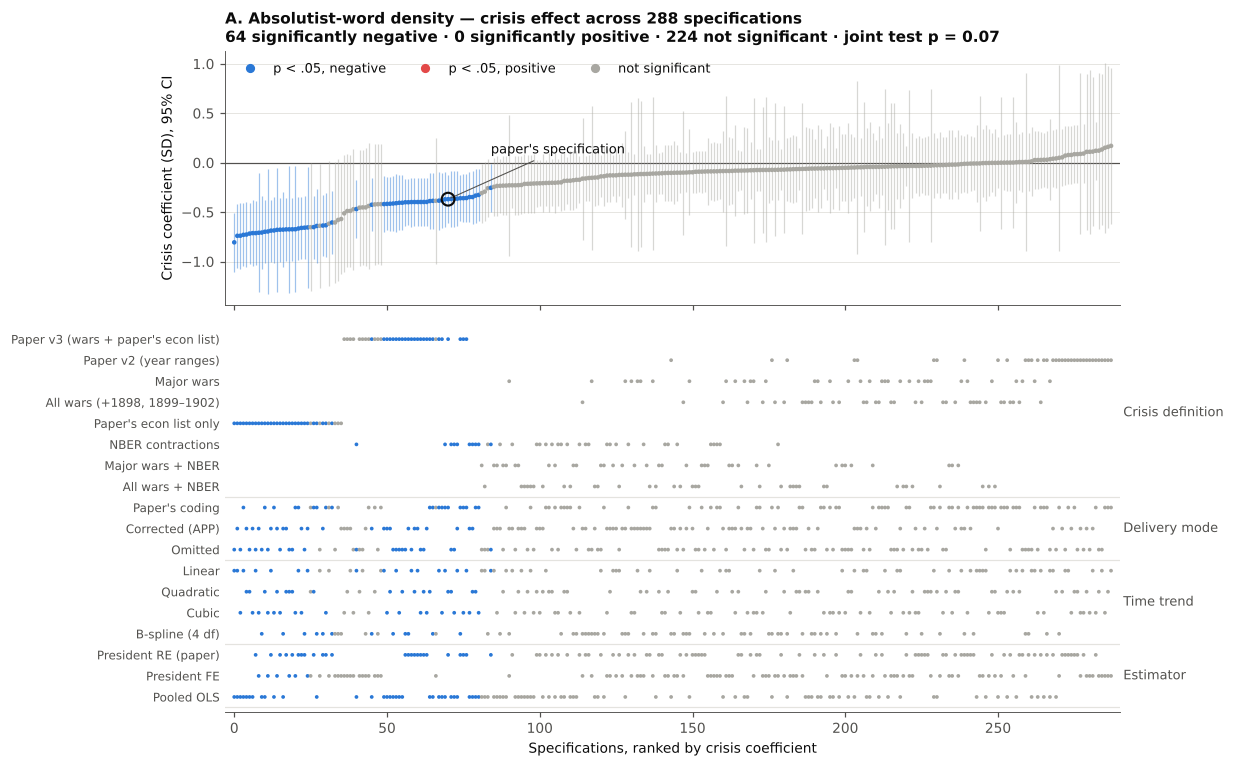

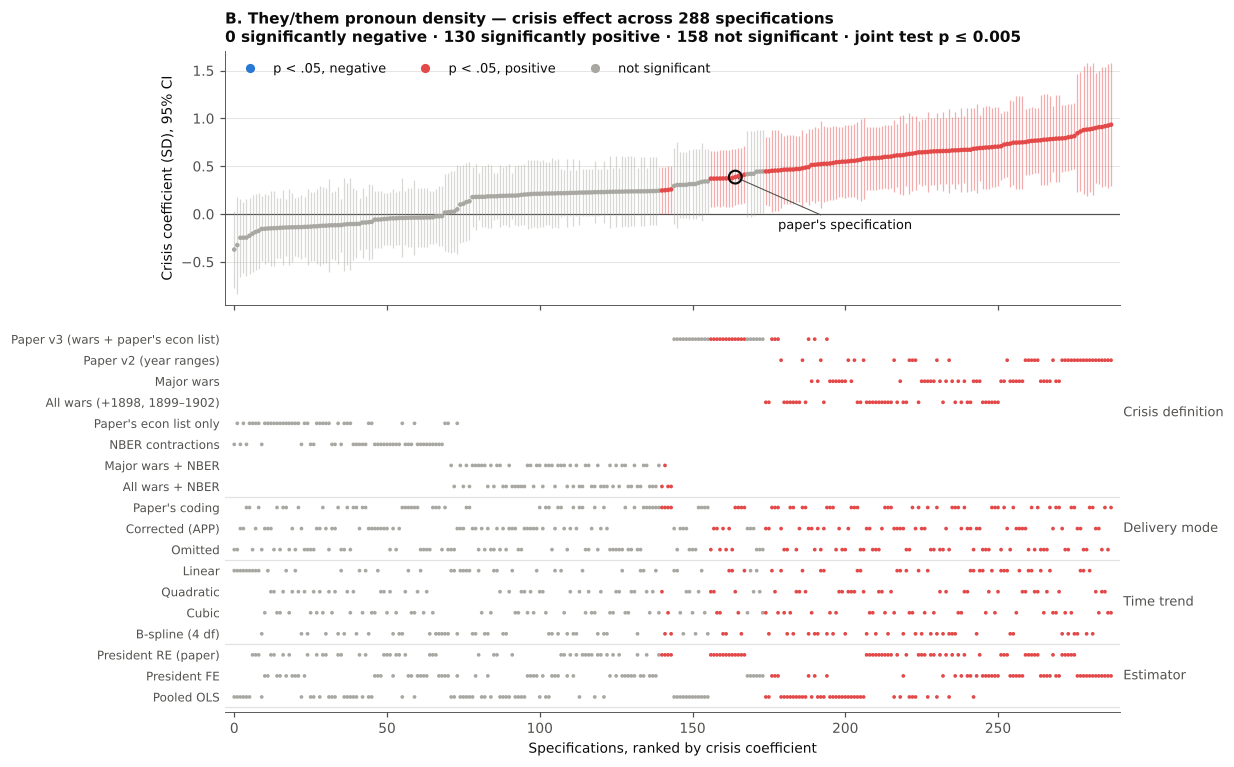

In [15]:
# Figure R2/R3: full specification curves for the paper's headline Study 2A result (absolutist words) and for the
# one outcome that is robust across specifications (they/them pronouns; not reported in the paper's Table 4).
DIMS = [("crisis", list(CRISIS)), ("delivery", list(DELIVERY)), ("trend", list(TIME)), ("estimator", ESTIMATORS)]
DIM_LABEL = {"crisis": "Crisis definition", "delivery": "Delivery mode", "trend": "Time trend", "estimator": "Estimator"}
TITLES = {"Absolutist_Density": "Absolutist-word density", "UsThem_Pronoun_Density": "Us-vs-them pronoun density",
          "They_Them_Density": "They/them pronoun density",
          "D_KL_Global": "Global KL divergence", "Yules_K": "Yule's K"}


def spec_curve(f, fig_name, letter):
    S = spec[spec.outcome == f].sort_values("beta").reset_index(drop=True)
    x = np.arange(len(S))
    col = np.where(S.p >= .05, GRAY, np.where(S.beta > 0, RED, BLUE))
    nrows = sum(len(v) for _, v in DIMS)
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(10.5, 7.8), sharex=True,
                                 gridspec_kw=dict(height_ratios=[1.05, 1.6], hspace=0.06))
    a1.axhline(0, color=INK2, lw=0.8)
    a1.vlines(x, S.beta - 1.96 * S.se, S.beta + 1.96 * S.se, color=col, lw=0.8, alpha=0.45)
    a1.scatter(x, S.beta, c=col, s=9, zorder=3, linewidths=0)
    k = S.index[S.paper_spec][0]
    a1.scatter([k], [S.beta[k]], s=70, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=4)
    a1.annotate("paper's specification", (k, S.beta[k]), xytext=(28, -34 if S.beta[k] > 0 else 30),
                textcoords="offset points", fontsize=8.5, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK2, lw=0.7))
    pos, neg = ((S.p < .05) & (S.beta > 0)).sum(), ((S.p < .05) & (S.beta < 0)).sum()
    a1.set_ylabel("Crisis coefficient (SD), 95% CI")
    J = joint[joint.outcome == f].iloc[0]
    a1.set_title(f"{letter}. {TITLES.get(f, f)} — crisis effect across {len(S)} specifications\n"
                 f"{neg} significantly negative · {pos} significantly positive · {len(S) - pos - neg} not significant · "
                 f"joint test {fmt_jp(J.joint_p_share)}", loc="left", fontsize=10, fontweight="bold")
    a1.grid(axis="x", visible=False)
    handles = [plt.Line2D([], [], marker="o", ls="", color=c_, label=l_, ms=5)
               for c_, l_ in [(BLUE, "p < .05, negative"), (RED, "p < .05, positive"), (GRAY, "not significant")]]
    a1.legend(handles=handles, loc="upper left", fontsize=8.5, ncol=3)

    yticks, ylabels, r = [], [], 0
    for dim, opts in DIMS:
        for o in opts:
            on = (S[dim] == o).values
            a2.scatter(x[on], np.full(on.sum(), -r), c=col[on], s=6, linewidths=0)
            yticks.append(-r); ylabels.append(o); r += 1
        a2.axhline(-r + 0.5, color=GRID, lw=0.8)
        a2.text(len(S) + 3, -(r - len(opts) / 2 - 0.5), DIM_LABEL[dim], fontsize=8.5, color=INK2, va="center")
    a2.set_yticks(yticks); a2.set_yticklabels(ylabels, fontsize=7.8)
    a2.set_ylim(-r + 0.3, 0.7)
    a2.set_xlim(-3, len(S) + 2)
    a2.grid(visible=False)
    a2.set_xlabel("Specifications, ranked by crisis coefficient")
    a2.spines["left"].set_visible(False)
    a2.tick_params(axis="y", length=0)
    save(fig, fig_name)
    plt.show()


spec_curve("Absolutist_Density", "Figure_R2_Study2A_speccurve_absolutist", "A")
spec_curve("They_Them_Density", "Figure_R3_Study2A_speccurve_theythem", "B")

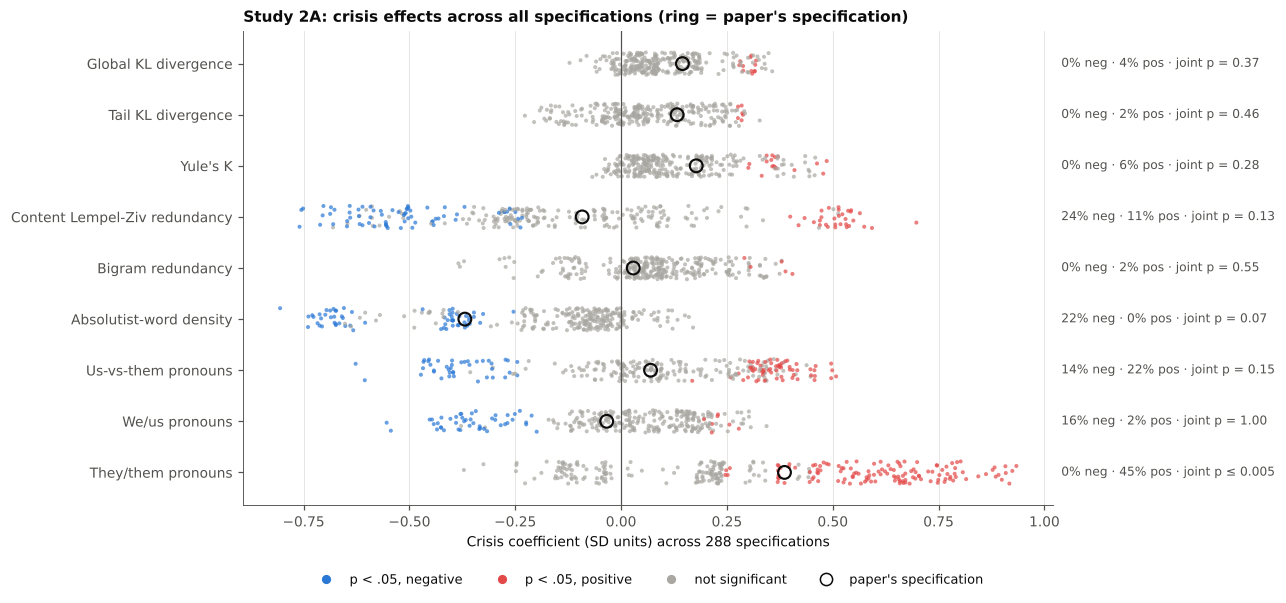

In [16]:
# Figure R4: every outcome at once — where the paper's estimate sits in the distribution of 288 specifications.
fig, ax = plt.subplots(figsize=(9.5, 5.6))
order = OUTCOMES[::-1]
labels = {"D_KL_Global": "Global KL divergence", "D_KL_Tail": "Tail KL divergence", "Yules_K": "Yule's K",
          "R_LZ_Content": "Content Lempel-Ziv redundancy", "Bigram_Redundancy": "Bigram redundancy",
          "Absolutist_Density": "Absolutist-word density", "UsThem_Pronoun_Density": "Us-vs-them pronouns",
          "We_Us_Density": "We/us pronouns", "They_Them_Density": "They/them pronouns"}
ax.axvline(0, color=INK2, lw=0.8)
for i, f in enumerate(order):
    S = spec[spec.outcome == f]
    col = np.where(S.p >= .05, GRAY, np.where(S.beta > 0, RED, BLUE))
    ax.scatter(S.beta, i + RNG.uniform(-0.22, 0.22, len(S)), c=col, s=7, alpha=0.7, linewidths=0)
    pap = S[S.paper_spec].iloc[0]
    ax.scatter([pap.beta], [i], s=70, facecolor="none", edgecolor=INK, linewidth=1.4, zorder=4)
    J = joint[joint.outcome == f].iloc[0]
    ax.text(1.01, i, f"{J.pct_sig_neg:.0f}% neg · {J.pct_sig_pos:.0f}% pos · joint {fmt_jp(J.joint_p_share)}",
            transform=ax.get_yaxis_transform(), fontsize=8, color=INK2, va="center")
ax.set_yticks(range(len(order))); ax.set_yticklabels([labels[o] for o in order])
ax.set_xlabel("Crisis coefficient (SD units) across 288 specifications")
ax.set_title("Study 2A: crisis effects across all specifications (ring = paper's specification)",
             loc="left", fontsize=10, fontweight="bold")
ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=c_, label=l_, ms=5)
           for c_, l_ in [(BLUE, "p < .05, negative"), (RED, "p < .05, positive"), (GRAY, "not significant")]]
handles.append(plt.Line2D([], [], marker="o", ls="", mfc="none", mec=INK, label="paper's specification", ms=8))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8.5)
save(fig, "Figure_R4_Study2A_all_outcomes")
plt.show()

# Part 4 — Study 2B: within-user conversational coupling (Table 7, Figure 5)

Input: the window-level matrix the paper exports (`data/study2b_isis_longitudinal_w150_no_hashtags.csv`,
785 windows from 56 accounts, retweets and hashtags removed, timelines in chronological order).

The paper's Table 5A fits a random intercept per account. Five checks:
1. **Random slopes.** A within-user effect estimated with a random intercept only treats every account as having
   the same slope; if slopes differ between accounts, the standard error is too small (Barr et al., 2013).
2. **User fixed effects with clustered errors.** Compares each window only with other windows from the same account;
   *p* from a wild cluster bootstrap by account (Webb weights, 999 draws).
3. **Influence.** Seven accounts supply over half the windows. Re-estimated with at most 20 windows per account
   (evenly spaced across each timeline) and without the three largest accounts.
4. **Trait vs state.** "Within-user effect not significant, between-user effect significant" is not evidence that
   the two differ. The Mundlak contextual coefficient tests the difference directly.
5. **Specification curve and joint test.** 3 estimators × 3 covariate sets × 3 samples × 2 coupling scales
   (person-centred φ, or within-account percentile rank) = 54 specifications per outcome. The joint test rotates
   each account's coupling sequence by a random offset, keeping its values, mean and autocorrelation but breaking
   the link with the text; 999 draws. Two joint statistics, as in Part 3: the median coefficient across
   specifications, and the share significant in the dominant direction. They can disagree: a small effect that
   is consistent in sign but rarely significant on its own gives a small median p and a large share p.

Effects are reported in SD of the outcome per within-account SD of coupling. Holm correction is applied across
the 8 outcomes.

In [17]:
TL = pd.read_csv(find_repo_file("data/study2b_isis_longitudinal_w150_no_hashtags.csv"))
TL = TL.sort_values(["User", "Career_Stage_Tau"]).reset_index(drop=True)
OUT_2B = ["R_LZ_Content", "D_KL_Global", "D_KL_Tail", "Yules_K",
          "Absolutist_Density", "UsThem_Pronoun_Density", "We_Us_Density", "They_Them_Density"]
LAB_2B = {"R_LZ_Content": "Content Lempel-Ziv redundancy", "D_KL_Global": "Global KL divergence",
          "D_KL_Tail": "Tail KL divergence", "Yules_K": "Yule's K", "Absolutist_Density": "Absolutist-word density",
          "UsThem_Pronoun_Density": "Us-vs-them pronouns", "We_Us_Density": "We/us pronouns",
          "They_Them_Density": "They/them pronouns"}
vc = TL.User.value_counts()
print(f"{len(TL)} windows from {TL.User.nunique()} accounts; windows per account: median {vc.median():.0f}, max {vc.max()}")
print(f"3 largest accounts supply {vc.head(3).sum() / len(TL):.0%} of windows; 7 largest supply {vc.head(7).sum() / len(TL):.0%}")
print("Note: the `User` column holds raw account handles. The paper's ethics statement says handles are not "
      "redistributed — replace them with hashed IDs before release.")

# Check: the paper's specification reproduces Table 5A.
FX_PAPER = "Within_User_Phi_Dev + User_Mean_Phi + Tweets_In_Window + Career_Stage_Tau"
rep = []
for f in OUT_2B:
    m = smf.mixedlm(f"{f} ~ {FX_PAPER}", TL, groups=TL["User"]).fit(reml=True)
    rep.append(dict(outcome=f, within_beta=m.params["Within_User_Phi_Dev"], within_p=m.pvalues["Within_User_Phi_Dev"],
                    between_beta=m.params["User_Mean_Phi"], between_p=m.pvalues["User_Mean_Phi"]))
print("\nPaper's specification (should match Table 5A, raw units):")
print(pd.DataFrame(rep).to_string(index=False, float_format=lambda v: f"{v:.4g}"))

785 windows from 56 accounts; windows per account: median 6, max 100
3 largest accounts supply 36% of windows; 7 largest supply 54%
Note: the `User` column holds raw account handles. The paper's ethics statement says handles are not redistributed — replace them with hashed IDs before release.



Paper's specification (should match Table 5A, raw units):
               outcome  within_beta  within_p  between_beta  between_p
          R_LZ_Content     -0.02384 4.314e-07      -0.02764    0.01161
           D_KL_Global       -0.032  0.005359      -0.02571     0.2881
             D_KL_Tail     -0.00953    0.1183     -0.009057     0.5244
               Yules_K       -12.29   0.02872        -2.261      0.855
    Absolutist_Density    0.0007185    0.5865       0.00629  0.0006919
UsThem_Pronoun_Density     0.006156   0.03669       0.02231  1.798e-05
         We_Us_Density     0.001281     0.416       0.01307  4.563e-05
     They_Them_Density     0.004953   0.04811      0.009616    0.01519


In [18]:
SD_Y = {f: TL[f].std() for f in OUT_2B}                          # fixed reference scales so samples stay comparable
SD_W = (TL.Window_Phi - TL.groupby("User").Window_Phi.transform("mean")).std()
SD_B = TL.groupby("User").Window_Phi.mean().std()
_pct = TL.Window_Phi.groupby(TL.User).rank(pct=True)
SD_R = (_pct - _pct.groupby(TL.User).transform("mean")).std()
SAMPLES = ["All windows", "≤ 20 windows per account", "Without 3 largest accounts"]
COVS = {"None": "", "Tweets in window": " + Tweets_In_Window", "Tweets + career stage (paper)": " + Tweets_In_Window + Career_Stage_Tau"}
SCALES = ["Person-centred φ (paper)", "Within-account percentile rank"]
EST_2B = ["User RI (paper)", "User RI + random slope", "User FE, clustered SE"]


def sample_frame(name):
    if name == "All windows":
        D = TL.copy()
    elif name == "≤ 20 windows per account":
        keep = []
        for _, g in TL.groupby("User", sort=False):
            idx = g.index.values
            keep.extend(idx if len(idx) <= 20 else idx[np.unique(np.linspace(0, len(idx) - 1, 20).round().astype(int))])
        D = TL.loc[sorted(keep)].copy()
    else:
        D = TL[~TL.User.isin(vc.head(3).index)].copy()
    return D.reset_index(drop=True)


def add_terms(D, phi=None):
    """Within- and between-account coupling terms (SD-scaled); phi lets the joint test pass rotated values."""
    phi = D["Window_Phi"].values if phi is None else phi
    s = pd.Series(phi, index=D.index)
    mean_u = s.groupby(D["User"]).transform("mean")
    D["w_dev"] = (s - mean_u) / SD_W
    pct = s.groupby(D["User"]).rank(pct=True)
    pct_c = pct - pct.groupby(D["User"]).transform("mean")
    D["w_rank"] = pct_c / SD_R
    D["b_mean"] = (mean_u - TL.Window_Phi.mean()) / SD_B
    D["phi_raw"] = (s - TL.Window_Phi.mean()) / SD_W
    return D


def fwl_cluster(X0, y, C, groups):
    """Coefficient(s) on columns of C after partialling out X0; CR1 cluster-robust SE; t with G-1 df."""
    Q, R = np.linalg.qr(X0)
    Q = Q[:, : int(np.sum(np.abs(np.diag(R)) > 1e-10 * np.abs(R).max()))]
    yr = y - Q @ (Q.T @ y)
    Cr = C - Q @ (Q.T @ C)
    sxx = (Cr**2).sum(0)
    beta = (Cr.T @ yr) / sxx
    E = yr[:, None] - Cr * beta[None, :]
    G_ = groups.max() + 1
    scores = np.zeros((G_, C.shape[1]))
    np.add.at(scores, groups, Cr * E)
    n, k = len(y), Q.shape[1] + 1
    V = (G_ / (G_ - 1)) * ((n - 1) / (n - k)) * (scores**2).sum(0) / sxx**2
    t = beta / np.sqrt(V)
    return beta, np.sqrt(V), 2 * stats.t.sf(np.abs(t), G_ - 1), Q, yr, Cr


def fe_design(D, cov):
    return np.asarray(patsy.dmatrix("C(User)" + cov, D, return_type="dataframe"))


def wild_fe_p(D, f, cov, wcol="w_dev", B=999):
    y = (D[f].values - D[f].mean()) / SD_Y[f]
    g = pd.factorize(D["User"])[0]
    beta, se, p, Q, yr, Cr = fwl_cluster(fe_design(D, cov), y, D[[wcol]].values, g)
    t_obs = beta[0] / se[0]
    c = Cr[:, 0]; sxx = c @ c; G_ = g.max() + 1
    W = WEBB[RNG.integers(0, 6, size=(B, G_))]
    Ys = W[:, g] * yr[None, :]                                    # restricted residuals (beta = 0), wild draws
    Ys = Ys - (Ys @ Q) @ Q.T
    b = (Ys @ c) / sxx
    E = Ys - b[:, None] * c[None, :]
    S_ = np.zeros((B, G_)); np.add.at(S_.T, g, (E * c[None, :]).T)
    tb = b / np.sqrt((G_ / (G_ - 1)) * (S_**2).sum(1) / sxx**2)
    return beta[0], (1 + np.sum(np.abs(tb) >= abs(t_obs))) / (B + 1)


def fit_2b(D, f, est, cov, wcol):
    D = D.assign(Z=(D[f] - D[f].mean()) / SD_Y[f])
    if est == "User FE, clustered SE":
        b, se, p, *_ = fwl_cluster(fe_design(D, cov), D["Z"].values, D[[wcol]].values, pd.factorize(D["User"])[0])
        return b[0], se[0], p[0], True
    re = f"~{wcol}" if est == "User RI + random slope" else None
    m = smf.mixedlm(f"Z ~ {wcol} + b_mean{cov}", D, groups=D["User"], re_formula=re).fit(reml=True)
    return m.params[wcol], m.bse[wcol], m.pvalues[wcol], bool(m.converged)


FRAMES = {s_: add_terms(sample_frame(s_)) for s_ in SAMPLES}
for s_, D in FRAMES.items():
    print(f"  {s_:28s} {len(D):4d} windows, {D.User.nunique()} accounts")

  All windows                   785 windows, 56 accounts
  ≤ 20 windows per account      503 windows, 56 accounts
  Without 3 largest accounts    505 windows, 53 accounts


In [19]:
# Main table: paper's covariates, all windows, person-centred coupling.
D = FRAMES["All windows"]
cov = COVS["Tweets + career stage (paper)"]
main = []
for f in OUT_2B:
    r = dict(outcome=f)
    for est in EST_2B:
        b, se, p, conv = fit_2b(D, f, est, cov, "w_dev")
        r[est] = (b, se, p, conv)
    _, r["fe_wild_p"] = wild_fe_p(D, f, cov)
    for s_ in ["≤ 20 windows per account", "Without 3 largest accounts"]:
        r[s_] = fit_2b(FRAMES[s_], f, "User RI + random slope", cov, "w_dev")
    # Mundlak: with the raw (uncentred) coupling term, the coefficient on the account mean = between − within
    Dz = D.assign(Z=(D[f] - D[f].mean()) / SD_Y[f])
    mm = smf.mixedlm(f"Z ~ phi_raw + b_mean{cov}", Dz, groups=Dz["User"], re_formula="~phi_raw").fit(reml=True)
    mb = smf.mixedlm(f"Z ~ w_dev + b_mean{cov}", Dz, groups=Dz["User"]).fit(reml=True)
    r["between"] = (mb.params["b_mean"], mb.pvalues["b_mean"])
    r["between_minus_within_p"] = mm.pvalues["b_mean"]
    main.append(r)

ps_rs = np.array([r["User RI + random slope"][2] for r in main])
order_ = np.argsort(ps_rs)
holm = np.empty_like(ps_rs)
holm[order_] = np.minimum(1, np.maximum.accumulate((len(ps_rs) - np.arange(len(ps_rs))) * ps_rs[order_]))

rows_main = []
for r, h in zip(main, holm):
    rows_main.append({
        "outcome": LAB_2B[r["outcome"]],
        "RI (paper)": f"{r['User RI (paper)'][0]:+.3f} ({fmt_p(r['User RI (paper)'][2])})",
        "RI + slope": f"{r['User RI + random slope'][0]:+.3f} ({fmt_p(r['User RI + random slope'][2])})"
                      + ("" if r["User RI + random slope"][3] else "*"),
        "Holm": fmt_p(h),
        "FE (wild p)": f"{r['User FE, clustered SE'][0]:+.3f} ({fmt_p(r['fe_wild_p'])})",
        "≤20/acct": f"{r['≤ 20 windows per account'][0]:+.3f} ({fmt_p(r['≤ 20 windows per account'][2])})",
        "no top-3": f"{r['Without 3 largest accounts'][0]:+.3f} ({fmt_p(r['Without 3 largest accounts'][2])})",
        "between (p)": f"{r['between'][0]:+.3f} ({fmt_p(r['between'][1])})",
        "between≠within p": fmt_p(r["between_minus_within_p"]),
    })
main_tab = pd.DataFrame(rows_main)
print("Within-account coupling effect, SD of outcome per within-account SD of coupling (p).")
print("RI + slope, ≤20/acct and no top-3 use random slopes; * = mixed model did not report convergence.\n")
print(main_tab.to_string(index=False))
pd.DataFrame([{**{"outcome": r["outcome"]},
               **{f"{e}_{k}": v for e in EST_2B for k, v in zip(["beta", "se", "p", "converged"], r[e])},
               "FE_wild_p": r["fe_wild_p"], "RS_holm_p": h,
               "cap20_beta": r["≤ 20 windows per account"][0], "cap20_p": r["≤ 20 windows per account"][2],
               "drop3_beta": r["Without 3 largest accounts"][0], "drop3_p": r["Without 3 largest accounts"][2],
               "between_beta": r["between"][0], "between_p": r["between"][1],
               "between_minus_within_p": r["between_minus_within_p"]} for r, h in zip(main, holm)]
             ).to_csv(os.path.join(OUT, "study2b_robustness_main.csv"), index=False)

Within-account coupling effect, SD of outcome per within-account SD of coupling (p).
RI + slope, ≤20/acct and no top-3 use random slopes; * = mixed model did not report convergence.

                      outcome       RI (paper)      RI + slope  Holm    FE (wild p)       ≤20/acct       no top-3      between (p) between≠within p
Content Lempel-Ziv redundancy -0.156 (4.3e-07)  -0.112 (0.040) 0.285 -0.148 (0.025) -0.080 (0.162) -0.086 (0.174)   -0.241 (0.012)            0.866
         Global KL divergence   -0.090 (0.005)  -0.077 (0.166) 0.829 -0.079 (0.178) -0.039 (0.490) -0.086 (0.196)   -0.096 (0.288)            0.733
           Tail KL divergence   -0.049 (0.118)  -0.038 (0.452) 1.000 -0.039 (0.522) -0.001 (0.988) -0.048 (0.414)   -0.062 (0.524)            0.665
                     Yule's K   -0.070 (0.029)  -0.051 (0.393) 1.000 -0.060 (0.191) -0.015 (0.800) -0.050 (0.488)   -0.017 (0.855)            0.667
      Absolutist-word density   +0.019 (0.586) -0.006 (0.936)* 1.000 +0.016 (

In [20]:
# Specification curve (54 per outcome) and within-account circular-shift joint test (FE specifications, 999 draws).
WCOL = {"Person-centred φ (paper)": "w_dev", "Within-account percentile rank": "w_rank"}
spec2b = []
for f in OUT_2B:
    for s_, (cn, cv), sc, est in itertools.product(SAMPLES, COVS.items(), SCALES, EST_2B):
        b, se, p, conv = fit_2b(FRAMES[s_], f, est, cv, WCOL[sc])
        spec2b.append(dict(outcome=f, sample=s_, covariates=cn, scale=sc, estimator=est, beta=b, se=se, p=p,
                           converged=conv,
                           paper_spec=(s_, cn, sc, est) == ("All windows", "Tweets + career stage (paper)",
                                                            "Person-centred φ (paper)", "User RI (paper)")))
spec2b = pd.DataFrame(spec2b)
spec2b.to_csv(os.path.join(OUT, "study2b_specification_curve.csv"), index=False)

R_DRAWS = 999
rot = {}
for s_, D in FRAMES.items():
    phi = D["Window_Phi"].values
    cols_dev, cols_rank = np.zeros((len(D), R_DRAWS)), np.zeros((len(D), R_DRAWS))
    blocks = [g.index.values for _, g in D.groupby("User", sort=False)]
    for r_ in range(R_DRAWS):
        new = phi.copy()
        for idx in blocks:
            new[idx] = np.roll(phi[idx], RNG.integers(1, len(idx)))
        Dr = add_terms(D.copy(), new)
        cols_dev[:, r_], cols_rank[:, r_] = Dr["w_dev"].values, Dr["w_rank"].values
    rot[s_] = {"w_dev": cols_dev, "w_rank": cols_rank}

joint2b = []
for f in OUT_2B:
    Bn, Pn = [], []
    for s_, (cn, cv), sc in itertools.product(SAMPLES, COVS.items(), SCALES):
        D = FRAMES[s_]
        y = ((D[f] - D[f].mean()) / SD_Y[f]).values
        b, _, p, *_ = fwl_cluster(fe_design(D, cv), y, rot[s_][WCOL[sc]], pd.factorize(D["User"])[0])
        Bn.append(b); Pn.append(p)
    Bn, Pn = np.array(Bn), np.array(Pn)
    S = spec2b[spec2b.outcome == f]
    O = S[S.estimator == "User FE, clustered SE"]
    obs_med = O.beta.median()
    obs_share = ((O.p < .05) & (np.sign(O.beta) == np.sign(obs_med))).mean()
    null_share = np.maximum(((Pn < .05) & (Bn > 0)).mean(0), ((Pn < .05) & (Bn < 0)).mean(0))
    pap = S[S.paper_spec].iloc[0]
    joint2b.append(dict(outcome=f, paper_beta=pap.beta, paper_p=pap.p, median_beta=S.beta.median(),
                        pct_sig_neg=100 * ((S.p < .05) & (S.beta < 0)).mean(),
                        pct_sig_pos=100 * ((S.p < .05) & (S.beta > 0)).mean(),
                        joint_p_median=(1 + np.sum(np.abs(np.median(Bn, 0)) >= abs(obs_med))) / (1 + R_DRAWS),
                        joint_p_share=(1 + np.sum(null_share >= obs_share)) / (1 + R_DRAWS)))
joint2b = pd.DataFrame(joint2b)
joint2b.to_csv(os.path.join(OUT, "study2b_joint_test.csv"), index=False)
print(f"Specification curve: {len(spec2b)} fits ({(~spec2b.converged).sum()} mixed models without a convergence flag)")
print(joint2b.round(3).to_string(index=False))
for f in ["R_LZ_Content", "D_KL_Global", "Yules_K", "They_Them_Density"]:
    S = spec2b[spec2b.outcome == f]
    print(f"\n{LAB_2B[f]}: % of specifications with p < .05, by choice")
    for dim in ["estimator", "sample", "covariates", "scale"]:
        print(S.groupby(dim).agg(median_beta=("beta", "median"),
                                 pct_sig=("p", lambda q: round(100 * (q < .05).mean(), 1))).round(3).to_string())

Specification curve: 432 fits (33 mixed models without a convergence flag)
               outcome  paper_beta  paper_p  median_beta  pct_sig_neg  pct_sig_pos  joint_p_median  joint_p_share
          R_LZ_Content      -0.156    0.000       -0.091       50.000        0.000           0.001          0.053
           D_KL_Global      -0.090    0.005       -0.084       24.074        0.000           0.003          0.240
             D_KL_Tail      -0.049    0.118       -0.041       12.963        0.000           0.085          1.000
               Yules_K      -0.070    0.029       -0.061       18.519        0.000           0.018          0.252
    Absolutist_Density       0.019    0.586        0.018        0.000        0.000           0.488          1.000
UsThem_Pronoun_Density       0.064    0.037        0.076        0.000       33.333           0.015          0.241
         We_Us_Density       0.026    0.416        0.051        0.000       16.667           0.072          0.189
     They_The

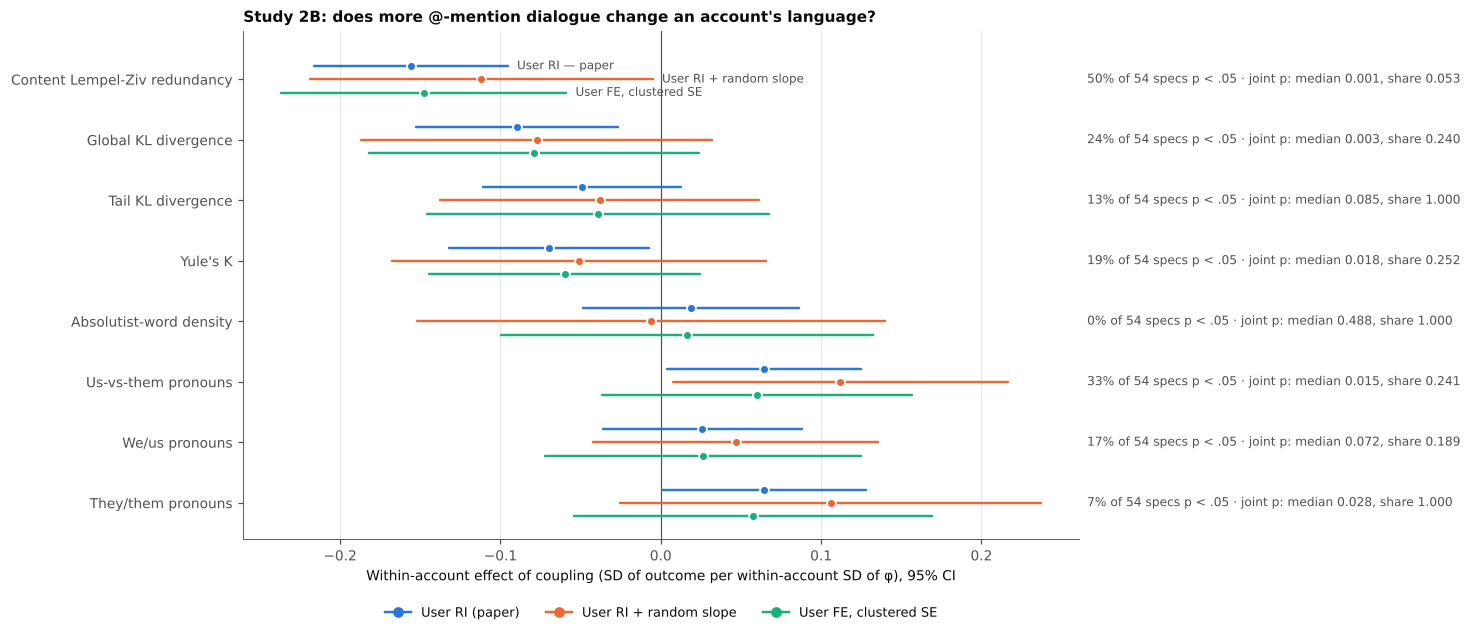

In [21]:
# Figure R5: within-account effect under three estimators (paper covariates, all windows, person-centred coupling).
fig, ax = plt.subplots(figsize=(9.8, 6.0))
EST_COL = {"User RI (paper)": BLUE, "User RI + random slope": ORANGE, "User FE, clustered SE": "#1baf7a"}
offs = {"User RI (paper)": 0.22, "User RI + random slope": 0.0, "User FE, clustered SE": -0.22}
order2b = OUT_2B[::-1]
ax.axvline(0, color=INK2, lw=0.8)
for i, r in enumerate([next(m for m in main if m["outcome"] == f) for f in order2b]):
    for est in EST_2B:
        b, se, p, _ = r[est]
        y_ = i + offs[est]
        ax.plot([b - 1.96 * se, b + 1.96 * se], [y_, y_], color=EST_COL[est], lw=1.6, solid_capstyle="round")
        ax.scatter([b], [y_], s=34, color=EST_COL[est], edgecolor="white", linewidth=1.2, zorder=3)
        if i == len(order2b) - 1:
            ax.annotate(est.replace(" (paper)", " — paper"), (b + 1.96 * se, y_), xytext=(6, 0),
                        textcoords="offset points", va="center", fontsize=7.8, color=INK2)
    J = joint2b[joint2b.outcome == r["outcome"]].iloc[0]
    sig = J.pct_sig_neg + J.pct_sig_pos
    ax.text(1.01, i, f"{sig:.0f}% of 54 specs p < .05 · joint p: median {J.joint_p_median:.3f}, share {J.joint_p_share:.3f}",
            transform=ax.get_yaxis_transform(), fontsize=8, color=INK2, va="center")
ax.set_yticks(range(len(order2b))); ax.set_yticklabels([LAB_2B[f] for f in order2b])
ax.set_ylim(-0.6, len(order2b) - 0.2)
ax.set_xlabel("Within-account effect of coupling (SD of outcome per within-account SD of φ), 95% CI")
ax.set_title("Study 2B: does more @-mention dialogue change an account's language?", loc="left",
             fontsize=10, fontweight="bold")
ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], color=c_, marker="o", lw=1.6, label=e_) for e_, c_ in EST_COL.items()]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.11), ncol=3, fontsize=8.5)
save(fig, "Figure_R5_Study2B_within_user")
plt.show()

## Files written to `robustness_outputs/`
- `study1a_outlet_level_results.csv` — every Study 1A estimate (both window definitions, both contrasts, four estimators)
- `study1a_leave_top_k_outlets.csv` — the leave-top-*k* curves
- `study1b_table3.csv`, `study1c_table4.csv`, `study1c_classification_auc.csv` — Tables 3 and 4 and the Study 1C AUCs
- `study2a_specification_curve.csv` — all 2,592 Study 2A specifications (9 outcomes × 288)
- `study2a_joint_test.csv` — per-outcome summary and circular-shift joint test (all 8 crisis definitions)
- `study2a_joint_test_by_crisis_family.csv` — the same test within war-based and economic definitions
- `study2b_robustness_main.csv`, `study2b_specification_curve.csv`, `study2b_joint_test.csv` — Study 2B checks
- `Figure_R1` … `Figure_R5` as PDF and PNG

In [22]:
for fn in sorted(os.listdir(OUT)):
    print(f"  {fn:55s} {os.path.getsize(os.path.join(OUT, fn)) / 1024:8.1f} KB")

  Figure_R1_Study1A_outlet_level.pdf                          51.4 KB
  Figure_R1_Study1A_outlet_level.png                         430.5 KB
  Figure_R2_Study2A_speccurve_absolutist.pdf                  53.5 KB
  Figure_R2_Study2A_speccurve_absolutist.png                 511.0 KB
  Figure_R3_Study2A_speccurve_theythem.pdf                    53.8 KB
  Figure_R3_Study2A_speccurve_theythem.png                   509.8 KB
  Figure_R4_Study2A_all_outcomes.pdf                          79.3 KB
  Figure_R4_Study2A_all_outcomes.png                         727.5 KB
  Figure_R5_Study2B_within_user.pdf                           38.1 KB
  Figure_R5_Study2B_within_user.png                          416.5 KB
  study1a_leave_top_k_outlets.csv                              3.3 KB
  study1a_outlet_level_results.csv                             8.9 KB
  study1b_table3.csv                                           3.4 KB
  study1c_classification_auc.csv                               0.6 KB
  study1c_table4.csv